# Projeto de Probabilidade e Estatística: Mediação Parental vs Riscos Digitais e Saúde Mental na Infância
## Linha de Pesquisa: "A Ilusão do Controle Parental? O Monitoramento dos Pais Protege Crianças contra Sofrimento Emocional e Riscos Online?"
### Base de Dados: Pesquisa TIC Kids Online Brasil 2025 (Cetic.br / NIC.br)

---

### Contextualização e Pergunta de Pesquisa
A crescente imersão de crianças e adolescentes no ambiente digital intensificou o debate sobre a eficácia das estratégias de **mediação parental**:
* *Softwares de controle, filtros de conteúdo, limitação de tempo de tela e monitoramento de mensagens realmente reduzem a exposição de crianças a conteúdos nocivos e ao sofrimento emocional na internet?*
* *Ou haverá uma "falsa sensação de segurança", na qual crianças e adolescentes encontram formas de burlar os controles técnicos, mantendo-se expostas a riscos sem o devido acolhimento dialógico?*

A pesquisa **TIC Kids Online Brasil 2025**, conduzida pelo **Cetic.br / NIC.br**, adota uma metodologia ímpar: entrevista **pares formados por uma criança/adolescente (de 9 a 17 anos) e seu respectivo responsável legal**, permitindo confrontar estatisticamente o que os pais acreditam controlar com a experiência real de risco e bem-estar emocional vivenciada pelos filhos.

### Estrutura do Estudo (5 Fases Sequenciais):
1. **Fase 1: Preparação, Limpeza e Pré-processamento dos Dados Pareados (Implementada nesta etapa)**
2. **Fase 2: Análise Exploratória de Dados (EDA) e Visualização Comparativa**
3. **Fase 3: Inferência Estatística e Testes de Hipóteses (Bivariados e Não Paramétricos)**
4. **Fase 4: Modelagem Multivariada (Regressão Logística Binária via Máxima Verossimilhança)**
5. **Fase 5: Síntese, Discussão Crítica e Conclusões para Políticas Públicas**

---
## FASE 1: Preparação, Limpeza e Pré-processamento dos Dados Pareados
Nesta fase inicial:
* Carregamos seletivamente as variáveis estratégicas dos blocos da criança e do responsável;
* Tratamos os códigos sentinela metodológicos (`97: Não sabe`, `98: Não respondeu`, `99: Não se aplica`);
* Decodificamos as categorias com base no **Dicionário Oficial da TIC Kids Online 2025**;
* Realizamos a engenharia de atributos (*Feature Engineering*) criando índices compostos de mediação técnica e indicadores de sofrimento emocional;
* Auditamos a integridade amostral e exportamos a base limpa para as fases subsequentes.


### 1.1 Configuração do Ambiente e Importação de Bibliotecas


In [2]:
import os
from pathlib import Path
import warnings
import numpy as np
import pandas as pd

# Ajustes de exibição do Pandas para relatórios analíticos
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: f'{x:.3f}')

print("✓ Ambiente computacional configurado com sucesso! Bibliotecas importadas.")


✓ Ambiente computacional configurado com sucesso! Bibliotecas importadas.


### 1.2 Leitura Seletiva dos Microdados da TIC Kids Online 2025
A base completa possui 369 colunas. Selecionamos **38 variáveis centrais** para a nossa linha de pesquisa, cobrindo o perfil demográfico, o controle técnico dos pais, a supervisão ativa e os desfechos de saúde mental e risco digital.


In [3]:
# Localiza a raiz do projeto tanto ao executar daqui quanto a partir da raiz.
project_root = Path.cwd()
while project_root != project_root.parent and not (project_root / 'controle_parental_digital').exists():
    project_root = project_root.parent

csv_kids_path = project_root / 'controle_parental_digital/tic_kids/tic_kids_online_brasil_2025_base_de_microdados_v1.0.csv'

# Seleção das colunas essenciais
colunas_selecionadas = [
    # Identificadores e Amostragem Probabilística
    'QUEST', 'ID_DOMICILIO', 'PESO',
    
    # Demografia da Criança / Adolescente
    'SEXO_KIDS', 'IDADE_KIDS', 'FAIXA_ETARIA', 'RACA_KIDS', 'ESC1',
    
    # Perfil do Responsável e Domicílio
    'RESP_SEXO', 'RESP_IDADE', 'ESCOLARIDADE_3', 'CLASSE_2015_REC', 'AREA', 'COD_REGIAO_2',
    
    # Bloco dos Pais: Mediação Técnica e Percepção de Segurança (GK1 e E3)
    'E3',          # Responsável acredita que a criança usa a internet com segurança
    'GK1_A',       # Usa recurso para bloquear/filtrar sites
    'GK1_B',       # Usa recurso para monitorar sites/apps acessados
    'GK1_C',       # Filtra aplicativos que a criança pode baixar
    'GK1_D',       # Alerta de compras em aplicativos
    'GK1_E',       # Limita o tempo na internet
    'GK1_F',       # Limita pessoas de contato (chamadas/mensagens)
    'GK1_G',       # Bloqueador de anúncios
    
    # Bloco da Criança: Percepção da Mediação e Evasão (U1, U5 e T26)
    'U1',          # Criança acha que pais sabem o que ela faz (Muito, Mais ou menos, Nada)
    'U5_A',        # Pais sentam junto participando do que faz
    'U5_B',        # Pais ficam por perto sem olhar
    'U5_C',        # Pais incentivam a aprender sozinho
    'U5_D',        # Pais sentam junto sem participar
    'U5_E',        # Pais olham o celular para ver o que faz / com quem fala
    'U5_F',        # Pais colocam regras para usar o celular
    'U5_G',        # Pais deixam de castigo sem celular
    'T26C_F',      # Criança já desativou filtros ou controles dos pais
    
    # Desfechos: Sofrimento Emocional, Riscos e Preocupação com Privacidade
    'M10_J',       # Frequência que fica chateada/incomodada com coisas na internet
    'T23_E',       # Viu informações sobre sofrimento emocional / saúde mental
    'T4_1',        # Viu imagens/vídeos de conteúdo sexual
    'T6',          # Ficou incomodada com as imagens de conteúdo sexual
    'T7_A',        # Já enviaram mensagens sobre sexo para a criança
    'T8',          # Ficou incomodada com mensagens
    'M10_O'        # Preocupação com a privacidade na internet
]

print(f"Carregando {len(colunas_selecionadas)} variáveis selecionadas da TIC Kids Online 2025...")
df_kids_raw = pd.read_csv(csv_kids_path, sep=';', usecols=colunas_selecionadas, decimal=',')

print("✓ Microdados pareados carregados com sucesso!")
print(f"Dimensões: {df_kids_raw.shape[0]:,} famílias (criança + responsável) e {df_kids_raw.shape[1]} atributos.")


Carregando 38 variáveis selecionadas da TIC Kids Online 2025...
✓ Microdados pareados carregados com sucesso!
Dimensões: 2,642 famílias (criança + responsável) e 38 atributos.


### 1.3 Tratamento de Códigos Sentinela Metodológicos
Seguindo os padrões técnicos do Cetic.br:
* `97`: Não sabe
* `98`: Não respondeu / Recusa
* `99`: Não se aplica (filtros do questionário, ex: crianças que não acessam internet ou itens não aplicáveis por corte de idade)

**Critérios de Tratamento:**
1. Variáveis técnicas dos pais (`GK1_A` a `GK1_G`): `1 = Sim`, `0 = Não`, `99 = 0` (não utiliza a ferramenta), `97/98 = NaN`.
2. Resposta de evasão da criança (`T26C_F`): `1 = Sim (desativou)`, `0 = Não`, `97/98/99 = NaN`.
3. Variáveis de risco e conteúdo sensível (`T4_1`, `T6`, `T7_A`, `T8`, `T23_E`): `1 = Sim`, `0 = Não`, `97/98 = NaN`.


In [4]:
df_k = df_kids_raw.copy()

# 1. Tratamento das variáveis de controle técnico dos pais (GK1)
gk1_cols = ['GK1_A', 'GK1_B', 'GK1_C', 'GK1_D', 'GK1_E', 'GK1_F', 'GK1_G']
for col in gk1_cols:
    df_k[col] = df_k[col].replace({97: np.nan, 98: np.nan, 99: 0})

# 2. Tratamento de variáveis binárias da criança
cols_binarias_kids = ['T26C_F', 'T23_E', 'T4_1', 'T6', 'T7_A', 'T8', 'E3']
for col in cols_binarias_kids:
    df_k[col] = df_k[col].replace({97: np.nan, 98: np.nan, 99: np.nan})

# 3. Tratamento de escalas ordinais de frequência (U5_A a U5_G e M10_J, M10_O)
# Códigos 1="Sempre", 2="Quase sempre", 3="Às vezes", 4="Quase nunca", 5="Nunca"
cols_escalas = ['U5_A', 'U5_B', 'U5_C', 'U5_D', 'U5_E', 'U5_F', 'U5_G', 'M10_J', 'M10_O']
for col in cols_escalas:
    df_k[col] = df_k[col].replace({97: np.nan, 98: np.nan, 99: np.nan})

print("✓ Códigos sentinela tratados com consistência e integridade estatística.")


✓ Códigos sentinela tratados com consistência e integridade estatística.


### 1.4 Decodificação e Mapeamento de Rótulos Categóricos Oficiais
Criamos variáveis categóricas semânticas conforme o dicionário da pesquisa para viabilizar análises exploratórias e inferenciais claras.


In [5]:
# Dicionários de decodificação
map_sexo = {1: 'Masculino', 2: 'Feminino'}

map_faixa_etaria_kids = {
    1: '9 a 10 anos',
    2: '11 a 12 anos',
    3: '13 a 14 anos',
    4: '15 a 17 anos'
}

map_classe_kids = {
    1: 'Classe AB',
    2: 'Classe C',
    3: 'Classe DE'
}

map_escolaridade_resp = {
    1: 'Até Fundamental I',
    2: 'Fundamental II',
    3: 'Médio ou mais'
}

map_regiao = {
    1: 'Sudeste',
    2: 'Nordeste',
    3: 'Sul',
    4: 'Norte',
    5: 'Centro-Oeste'
}

map_area = {
    1: 'Urbana',
    2: 'Rural'
}

map_conhecimento_pais = {
    1: 'Sabe Muito',
    2: 'Sabe Mais ou Menos',
    3: 'Não Sabe Nada'
}

# Criação das colunas descritivas
df_k['sexo_kids_desc'] = df_k['SEXO_KIDS'].map(map_sexo)
df_k['faixa_etaria_desc'] = pd.Categorical(df_k['FAIXA_ETARIA'].map(map_faixa_etaria_kids),
                                          categories=list(map_faixa_etaria_kids.values()), ordered=True)
df_k['classe_desc'] = pd.Categorical(df_k['CLASSE_2015_REC'].map(map_classe_kids),
                                     categories=['Classe DE', 'Classe C', 'Classe AB'], ordered=True)
df_k['escolaridade_resp_desc'] = pd.Categorical(df_k['ESCOLARIDADE_3'].map(map_escolaridade_resp),
                                               categories=list(map_escolaridade_resp.values()), ordered=True)
df_k['regiao_desc'] = df_k['COD_REGIAO_2'].map(map_regiao)
df_k['area_desc'] = df_k['AREA'].map(map_area)
df_k['sexo_resp_desc'] = df_k['RESP_SEXO'].map(map_sexo)
df_k['percepcao_conhecimento_pais'] = df_k['U1'].map(map_conhecimento_pais)

print("✓ Decodificação de rótulos categóricos oficiais concluída.")


✓ Decodificação de rótulos categóricos oficiais concluída.


### 1.5 Engenharia de Atributos (*Feature Engineering*)
Construímos indicadores analíticos que quantificam as dimensões teóricas de **controle**, **evasão** e **sofrimento emocional**:

1. **`score_controle_tecnico` (0 a 7):** Soma dos recursos técnicos utilizados pelo responsável (`GK1_A` a `GK1_G`: filtros de sites, monitoramento de apps, alerta de compras, etc.);
2. **`alto_controle_tecnico` (0 ou 1):** Indicador binário de famílias com intervenção técnica intensa (uso de $\ge 3$ ferramentas técnicas);
3. **`incomodo_emocional_recorrente` (0 ou 1):** Variável resposta primária construída a partir de `M10_J` (1 se a criança fica chateada/incomodada "Sempre", "Quase sempre" ou "Às vezes"; 0 se "Quase nunca" ou "Nunca");
4. **`busca_sofrimento_emocional` (0 ou 1):** Criança pesquisou sobre sentimentos, saúde mental ou sofrimento emocional (`T23_E`);
5. **`burlou_controle_pais` (0 ou 1):** Criança admite que já desativou filtros ou controles dos pais (`T26C_F`);
6. **`supervisao_invasiva` (0 ou 1):** Pais olham o celular com frequência alta para fiscalizar mensagens (`U5_E` $\le 2$).


In [6]:
# 1. Score Contínuo de Controle Técnico dos Pais (0 a 7)
df_k['score_controle_tecnico'] = df_k[gk1_cols].sum(axis=1)

# 2. Indicador Binário de Alto Controle Técnico (>= 3 recursos)
df_k['alto_controle_tecnico'] = (df_k['score_controle_tecnico'] >= 3).astype(int)

# 3. Desfecho Principal: Incômodo Emocional Recorrente na Rede (M10_J <= 3: Sempre/Quase Sempre/Às Vezes)
df_k['incomodo_emocional_recorrente'] = df_k['M10_J'].apply(lambda x: 1 if x in [1, 2, 3] else (0 if x in [4, 5] else np.nan))

# 4. Busca Ativa por Conteúdos de Sofrimento Emocional / Saúde Mental (T23_E)
df_k['busca_sofrimento_emocional'] = df_k['T23_E'].replace({1: 1, 0: 0})

# 5. Agência de Evasão: Criança Desativou Filtros dos Pais (T26C_F)
df_k['burlou_controle_pais'] = df_k['T26C_F'].replace({1: 1, 0: 0})

# 6. Supervisão Invasiva no Celular (U5_E <= 2: Pais olham celular Sempre ou Quase Sempre)
df_k['supervisao_invasiva'] = df_k['U5_E'].apply(lambda x: 1 if x in [1, 2] else (0 if x in [3, 4, 5] else np.nan))

# 7. Exposição a Conteúdos Sexuais (T4_1)
df_k['exposicao_conteudo_sexual'] = df_k['T4_1'].replace({1: 1, 0: 0})

print("--- Distribuição do Score de Controle Técnico dos Pais (0 a 7 recursos) ---")
print(df_k['score_controle_tecnico'].value_counts().sort_index())

print("\n--- Prevalência de Incômodo Emocional Recorrente (Amostra Válida) ---")
print(df_k['incomodo_emocional_recorrente'].value_counts(normalize=True).mul(100).round(2).astype(str) + '%')

print("\n--- Prevalência de Crianças que Burlaram Controles dos Pais ---")
print(df_k['burlou_controle_pais'].value_counts(normalize=True).mul(100).round(2).astype(str) + '%')


--- Distribuição do Score de Controle Técnico dos Pais (0 a 7 recursos) ---
score_controle_tecnico
0.000    1250
1.000     313
2.000     183
3.000     170
4.000     131
5.000     162
6.000     167
7.000     266
Name: count, dtype: int64

--- Prevalência de Incômodo Emocional Recorrente (Amostra Válida) ---
incomodo_emocional_recorrente
1.000    53.8%
0.000    46.2%
Name: proportion, dtype: str

--- Prevalência de Crianças que Burlaram Controles dos Pais ---
burlou_controle_pais
0.000    77.57%
1.000    22.43%
Name: proportion, dtype: str


### 1.6 Auditoria dos Dados Tratados e Resumo Inicial
Inspecionamos as frequências das variáveis criadas, a distribuição da idade da criança e cruzamentos preliminares.


In [7]:
print("==================================================")
print("             AUDITORIA DA BASE TIC KIDS 2025      ")
print("==================================================")
print(f"Total de Pares Entrevistados (Criança + Responsável): {len(df_k):,}")
print(f"Total de Atributos Finais: {df_k.shape[1]}")

print("\n--- Resumo da Idade das Crianças e Pesos Amostrais ---")
print(df_k[['IDADE_KIDS', 'RESP_IDADE', 'score_controle_tecnico', 'PESO']].describe())

# Tabela Cruzada Inicial: Controle Técnico dos Pais vs Incômodo Emocional da Criança
print("\n=== TABELA CRUZADA INICIAL: CONTROLE TÉCNICO vs INCÔMODO EMOCIONAL ===")
tab_cruzada = pd.crosstab(df_k['alto_controle_tecnico'].map({1: 'Alto Controle (3+ recursos)', 0: 'Baixo/Nenhum Controle'}),
                          df_k['incomodo_emocional_recorrente'].map({1: 'Incômodo Recorrente', 0: 'Sem Incômodo'}),
                          margins=True, margins_name="Total")
tab_cruzada_pct = pd.crosstab(df_k['alto_controle_tecnico'].map({1: 'Alto Controle (3+ recursos)', 0: 'Baixo/Nenhum Controle'}),
                              df_k['incomodo_emocional_recorrente'].map({1: 'Incômodo Recorrente', 0: 'Sem Incômodo'}),
                              normalize='index').mul(100).round(2)
print(tab_cruzada)
print("\nPercentual por linha:")
print(tab_cruzada_pct.astype(str) + '%')


             AUDITORIA DA BASE TIC KIDS 2025      
Total de Pares Entrevistados (Criança + Responsável): 2,642
Total de Atributos Finais: 53

--- Resumo da Idade das Crianças e Pesos Amostrais ---
       IDADE_KIDS  RESP_IDADE  score_controle_tecnico       PESO
count    2642.000    2642.000                2642.000   2642.000
mean       12.919      41.485                   2.039  10078.040
std         2.587      11.499                   2.521  20575.698
min         9.000      18.000                   0.000      4.853
25%        11.000      34.000                   0.000   1898.687
50%        13.000      40.000                   1.000   4350.368
75%        15.000      48.000                   4.000  10283.106
max        17.000      89.000                   7.000 494962.811

=== TABELA CRUZADA INICIAL: CONTROLE TÉCNICO vs INCÔMODO EMOCIONAL ===


incomodo_emocional_recorrente  Incômodo Recorrente  Sem Incômodo  Total
alto_controle_tecnico                                                  
Alto Controle (3+ recursos)                    466           387    853
Baixo/Nenhum Controle                          809           708   1517
Total                                         1275          1095   2370

Percentual por linha:
incomodo_emocional_recorrente Incômodo Recorrente Sem Incômodo
alto_controle_tecnico                                         
Alto Controle (3+ recursos)                54.63%       45.37%
Baixo/Nenhum Controle                      53.33%       46.67%


### 1.7 Exportação da Base Processada para as Próximas Fases
Gravamos o dataset higienizado e estruturado em `tic_kids_processada.csv`.


In [8]:
output_kids_csv = project_root / 'controle_parental_digital/tic_kids/tic_kids_processada.csv'
df_k.to_csv(output_kids_csv, index=False, sep=';', decimal='.')

tam_kb = os.path.getsize(output_kids_csv) / 1024
print(f"✓ Base processada gravada com sucesso em '{output_kids_csv}' ({tam_kb:.1f} KB).")
print("\n>>> FASE 1 DA TIC KIDS CONCLUÍDA COM SUCESSO! <<<")
print("Prontos para avançar para a FASE 2: Análise Exploratória de Dados (EDA) e Visualização Comparativa.")


✓ Base processada gravada com sucesso em '/home/lucas/Aulas/Probabilidade e Estatistisca/Projeto Final/controle_parental_digital/tic_kids/tic_kids_processada.csv' (631.0 KB).

>>> FASE 1 DA TIC KIDS CONCLUÍDA COM SUCESSO! <<<
Prontos para avançar para a FASE 2: Análise Exploratória de Dados (EDA) e Visualização Comparativa.


---
## FASE 2: Análise Exploratória de Dados (EDA) e Visualização Comparativa

Nesta fase, exploramos as relações empíricas entre o **comportamento de controle dos pais** e as **experiências de risco e bem-estar das crianças e adolescentes**:
1. **Arsenal de Controle Técnico:** Quais ferramentas de bloqueio e monitoramento os pais mais utilizam no Brasil?
2. **O Abismo de Percepção (Pais vs Filhos):** O que os pais acham que sabem em contraste com a percepção dos filhos e a capacidade de burlar os filtros?
3. **Controle Técnico vs Sofrimento Emocional:** Crianças com mais filtros de internet realmente relatam menos incômodo emocional e menos busca por conteúdos de saúde mental?
4. **Mediação Dialógica vs Supervisão Invasiva:** Conversar e orientar protege mais do que fiscalizar o celular e impor regras punitivas?
5. **Assimetrias de Gênero e Classe Social:** Como o controle parental e o sofrimento emocional se distribuem entre meninos e meninas e entre as classes AB, C e DE?


### 2.1 O Arsenal de Controle Técnico dos Pais: Prevalência Ponderada
Avaliamos a adesão dos responsáveis a cada uma das 7 ferramentas técnicas de mediação parental (`GK1_A` a `GK1_G`). Calculamos a estimativa ponderada pela amostragem complexa (`PESO`) para projetar a realidade das famílias brasileiras.


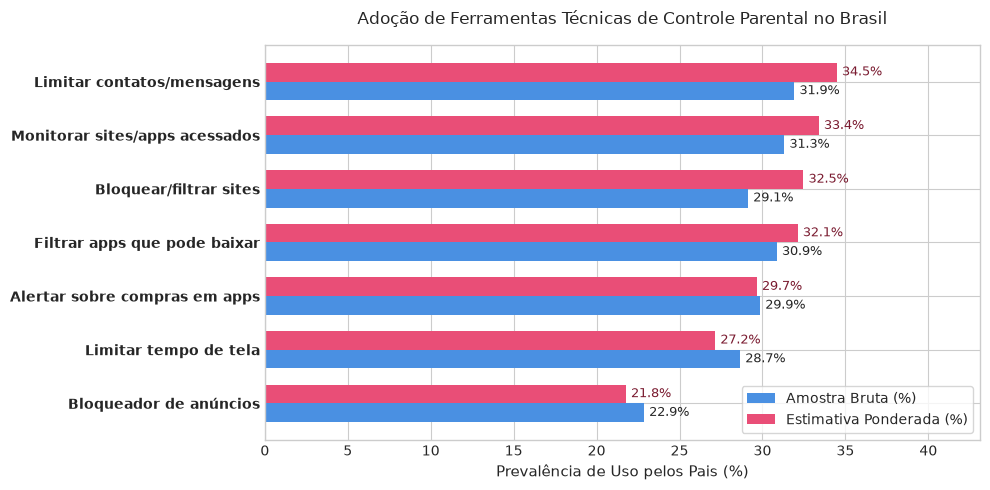

Tabela Detalhada de Adoção de Ferramentas Técnicas:


'               Recurso Técnico  Amostra (%)  Ponderada (%)\n    Limitar contatos/mensagens       31.927         34.491\nMonitorar sites/apps acessados       31.323         33.404\n        Bloquear/filtrar sites       29.141         32.473\n  Filtrar apps que pode baixar       30.875         32.132\n Alertar sobre compras em apps       29.867         29.667\n         Limitar tempo de tela       28.664         27.159\n        Bloqueador de anúncios       22.866         21.773'

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração de estilo visual
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

recursos_gk1 = {
    'Filtrar apps que pode baixar': 'GK1_C',
    'Bloquear/filtrar sites': 'GK1_A',
    'Monitorar sites/apps acessados': 'GK1_B',
    'Limitar tempo de tela': 'GK1_E',
    'Alertar sobre compras em apps': 'GK1_D',
    'Bloqueador de anúncios': 'GK1_G',
    'Limitar contatos/mensagens': 'GK1_F'
}

peso_total_k = df_k['PESO'].sum()
stats_recursos = []

for label, col in recursos_gk1.items():
    tx_amostral = df_k[col].mean() * 100
    tx_ponderada = (df_k[col] * df_k['PESO']).sum() / peso_total_k * 100
    stats_recursos.append({
        'Recurso Técnico': label,
        'Amostra (%)': tx_amostral,
        'Ponderada (%)': tx_ponderada
    })

df_recursos = pd.DataFrame(stats_recursos).sort_values(by='Ponderada (%)', ascending=True)

fig, ax = plt.subplots(figsize=(10, 5))
y_p = range(len(df_recursos))
w = 0.35

ax.barh([p - w/2 for p in y_p], df_recursos['Amostra (%)'], height=w, label='Amostra Bruta (%)', color='#4A90E2')
ax.barh([p + w/2 for p in y_p], df_recursos['Ponderada (%)'], height=w, label='Estimativa Ponderada (%)', color='#E94E77')

ax.set_yticks(y_p)
ax.set_yticklabels(df_recursos['Recurso Técnico'], fontweight='bold')
ax.set_xlabel('Prevalência de Uso pelos Pais (%)')
ax.set_title('Adoção de Ferramentas Técnicas de Controle Parental no Brasil', pad=15)
ax.legend(loc='lower right', frameon=True)

for p, (am, po) in enumerate(zip(df_recursos['Amostra (%)'], df_recursos['Ponderada (%)'])):
    ax.text(am + 0.3, p - w/2, f'{am:.1f}%', va='center', fontsize=9)
    ax.text(po + 0.3, p + w/2, f'{po:.1f}%', va='center', fontsize=9, color='#7A1B30')

ax.set_xlim(0, max(df_recursos['Ponderada (%)']) * 1.25)
plt.tight_layout()
plt.show()

print("Tabela Detalhada de Adoção de Ferramentas Técnicas:")
display(df_recursos.sort_values(by='Ponderada (%)', ascending=False).to_string(index=False))


### 2.2 O Confronto de Percepções e a Evasão Técnica: Pais vs Filhos
Investigamos o descompasso entre a segurança presumida pelos pais e a realidade vivenciada pelos filhos:
1. **O que os pais acreditam (`E3`):** Proporção de pais que acreditam que seus filhos navegam com total segurança;
2. **O que as crianças sabem (`U1`):** Crianças que afirmam que os pais "Não sabem nada" ou "Sabem mais ou menos" sobre suas atividades;
3. **A quebra de controle (`T26C_F`):** Taxa de crianças que **já desativaram os filtros dos pais**, segmentada por faixa etária.


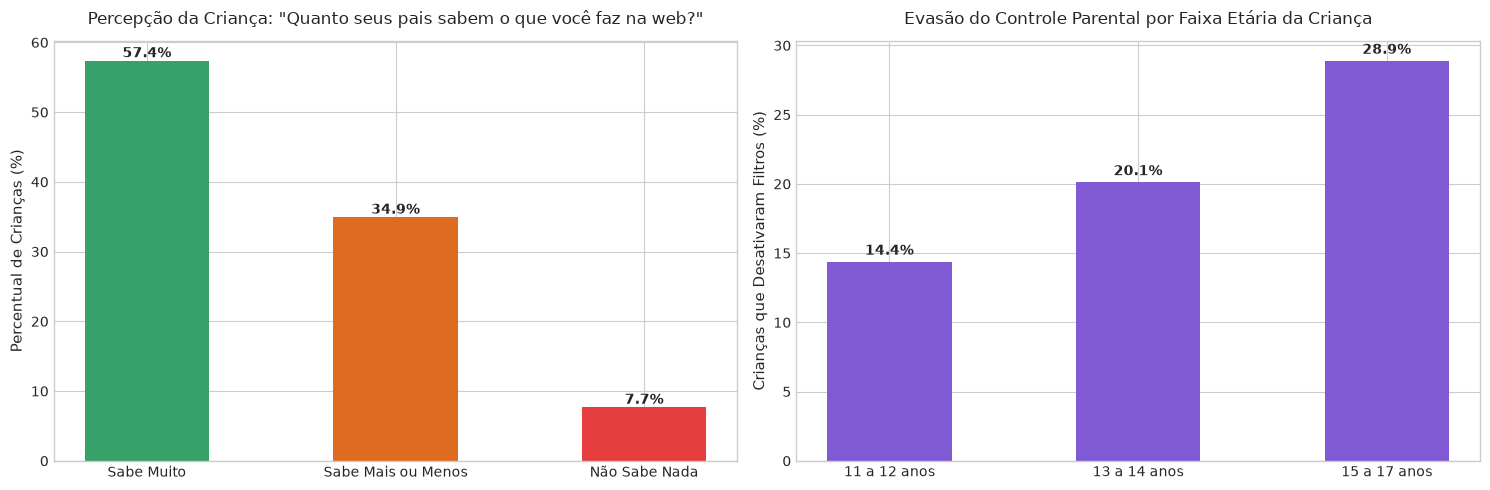

-> 77.3% dos pais brasileiros acreditam que seus filhos usam a internet com segurança.
-> Contudo, 42.6% das crianças afirmam que os pais sabem pouco ou nada sobre o que elas fazem online.
-> Entre os adolescentes de 15 a 17 anos, a taxa de evasão atinge 28.9%.


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Percepção dos Filhos sobre o Conhecimento dos Pais
df_u1 = df_k['percepcao_conhecimento_pais'].value_counts(normalize=True).mul(100)
cores_u1 = ['#38A169', '#DD6B20', '#E53E3E']
bars_u1 = axes[0].bar(df_u1.index, df_u1.values, color=cores_u1, width=0.5)
axes[0].set_ylabel('Percentual de Crianças (%)')
axes[0].set_title('Percepção da Criança: "Quanto seus pais sabem o que você faz na web?"', pad=12)
for bar in bars_u1:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, h + 0.5, f"{h:.1f}%", ha='center', fontweight='bold')

# 2. Evasão dos Filtros por Faixa Etária (Desativou Controles dos Pais)
faixas_evasao = df_k.groupby('faixa_etaria_desc')['burlou_controle_pais'].mean() * 100
bars_ev = axes[1].bar(faixas_evasao.index, faixas_evasao.values, color='#805AD5', width=0.5)
axes[1].set_ylabel('Crianças que Desativaram Filtros (%)')
axes[1].set_title('Evasão do Controle Parental por Faixa Etária da Criança', pad=12)
for bar in bars_ev:
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, h + 0.5, f"{h:.1f}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

# Taxa de confiança dos pais
tx_seguranca_pais = df_k['E3'].mean() * 100
print(f"-> {tx_seguranca_pais:.1f}% dos pais brasileiros acreditam que seus filhos usam a internet com segurança.")
print(f"-> Contudo, {df_u1['Sabe Mais ou Menos'] + df_u1['Não Sabe Nada']:.1f}% das crianças afirmam que os pais sabem pouco ou nada sobre o que elas fazem online.")
print(f"-> Entre os adolescentes de 15 a 17 anos, a taxa de evasão atinge {faixas_evasao['15 a 17 anos']:.1f}%.")


### 2.3 Controle Técnico dos Pais vs Desfechos de Sofrimento Emocional
Aqui testamos visualmente a hipótese central: **Crianças cujos pais utilizam mais ferramentas técnicas de bloqueio sofrem menos incômodo emocional na internet?**
Comparamos as taxas de:
* `incomodo_emocional_recorrente`: Criança fica chateada ou incomodada na rede;
* `busca_sofrimento_emocional`: Criança pesquisa sobre sentimentos, ansiedade ou sofrimento emocional.


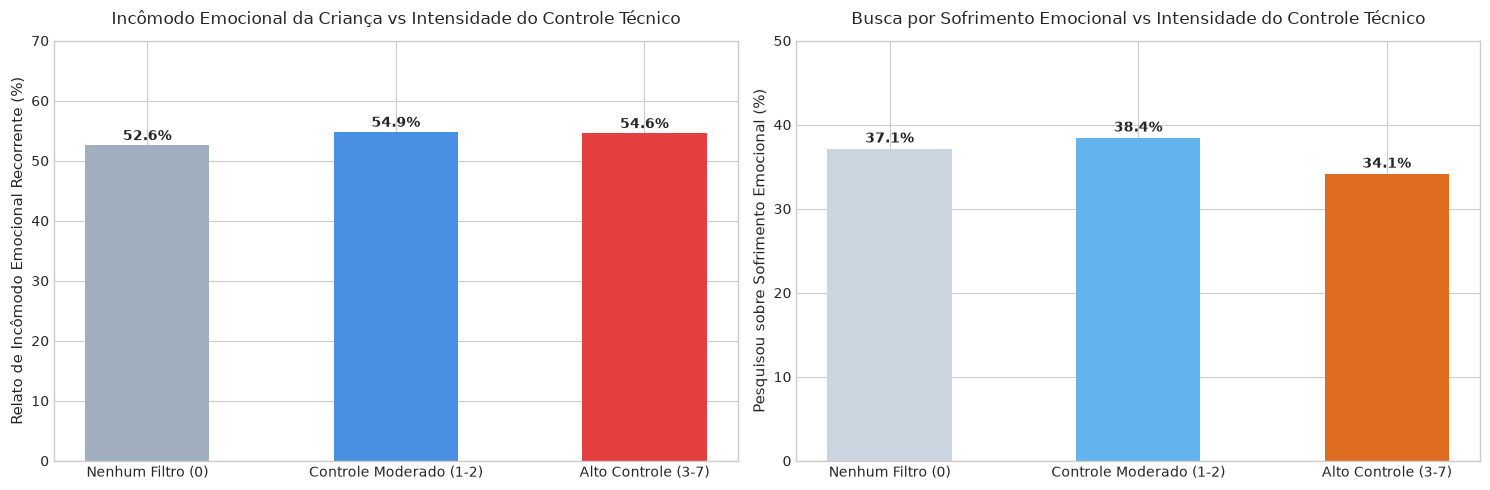

Tabela Comparativa: Controle Técnico vs Desfechos Emocionais dos Filhos:
                         Incômodo Emocional Recorrente (%)  \
categoria_controle                                           
Nenhum Filtro (0)                                   52.637   
Controle Moderado (1-2)                             54.852   
Alto Controle (3-7)                                 54.631   

                         Busca sobre Saúde Mental/Sofrimento (%)  
categoria_controle                                                
Nenhum Filtro (0)                                         37.080  
Controle Moderado (1-2)                                   38.380  
Alto Controle (3-7)                                       34.086  


In [11]:
# Criamos categorias de intensidade de controle técnico
def categorizar_controle(score):
    if score == 0:
        return 'Nenhum Filtro (0)'
    elif score in [1, 2]:
        return 'Controle Moderado (1-2)'
    else:
        return 'Alto Controle (3-7)'

df_k['categoria_controle'] = df_k['score_controle_tecnico'].apply(categorizar_controle)
cat_order = ['Nenhum Filtro (0)', 'Controle Moderado (1-2)', 'Alto Controle (3-7)']

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Incômodo Emocional por Nível de Controle Técnico
tx_incomodo = df_k.groupby('categoria_controle')['incomodo_emocional_recorrente'].mean().reindex(cat_order) * 100
bars_inc = axes[0].bar(cat_order, tx_incomodo, color=['#A0AEC0', '#4A90E2', '#E53E3E'], width=0.5)
axes[0].set_ylabel('Relato de Incômodo Emocional Recorrente (%)')
axes[0].set_title('Incômodo Emocional da Criança vs Intensidade do Controle Técnico', pad=12)
axes[0].set_ylim(0, 70)
for bar in bars_inc:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, h + 0.8, f"{h:.1f}%", ha='center', fontweight='bold')

# 2. Busca por Conteúdos de Saúde Mental / Sofrimento Emocional
tx_busca = df_k.groupby('categoria_controle')['busca_sofrimento_emocional'].mean().reindex(cat_order) * 100
bars_bsc = axes[1].bar(cat_order, tx_busca, color=['#CBD5E0', '#63B3ED', '#DD6B20'], width=0.5)
axes[1].set_ylabel('Pesquisou sobre Sofrimento Emocional (%)')
axes[1].set_title('Busca por Sofrimento Emocional vs Intensidade do Controle Técnico', pad=12)
axes[1].set_ylim(0, 50)
for bar in bars_bsc:
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, h + 0.8, f"{h:.1f}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

# Resumo numérico
print("Tabela Comparativa: Controle Técnico vs Desfechos Emocionais dos Filhos:")
comp_tab = pd.DataFrame({
    'Incômodo Emocional Recorrente (%)': tx_incomodo,
    'Busca sobre Saúde Mental/Sofrimento (%)': tx_busca
})
print(comp_tab)


### 2.4 Mediação Dialógica (Conversar) vs Supervisão Invasiva (Fiscalizar o Celular)
Investigamos dois estilos parentais contrastantes:
* **Mediação Dialógica/Participativa (`U5_A`):** Pais que sentam junto e conversam sobre o uso da rede;
* **Supervisão Invasiva (`U5_E`):** Pais que olham o celular com frequência para fiscalizar conversas e contatos.
Qual das abordagens apresenta menor correlação com o sofrimento emocional das crianças?


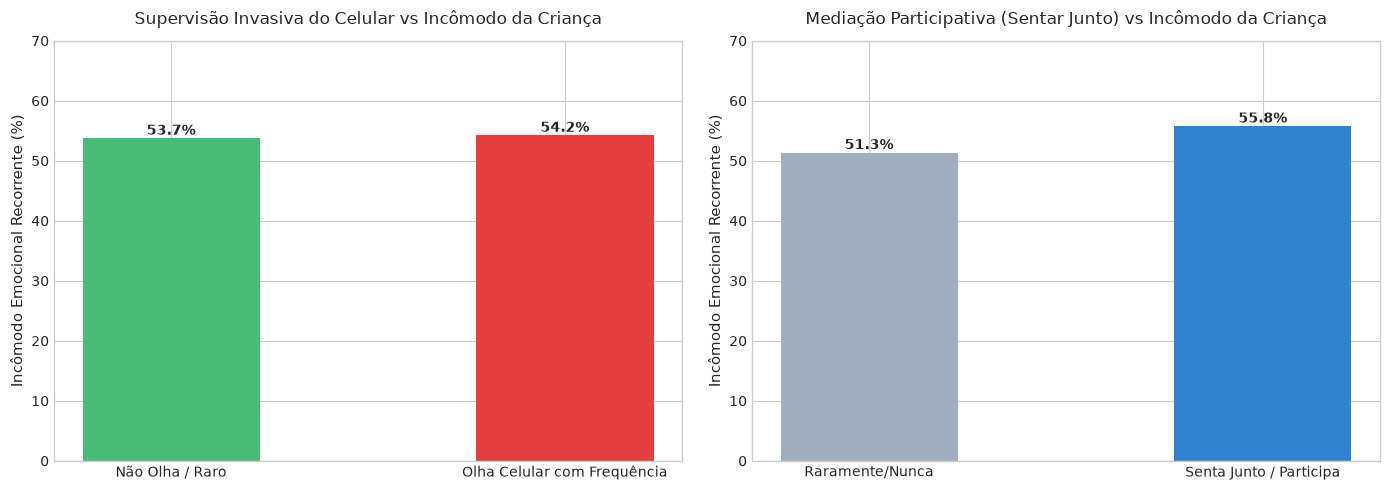

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Supervisão Invasiva (Olhar o celular) vs Incômodo Emocional
tx_inv = df_k.groupby('supervisao_invasiva')['incomodo_emocional_recorrente'].mean() * 100
axes[0].bar(['Não Olha / Raro', 'Olha Celular com Frequência'], tx_inv.values, 
            color=['#48BB78', '#E53E3E'], width=0.45)
axes[0].set_ylabel('Incômodo Emocional Recorrente (%)')
axes[0].set_title('Supervisão Invasiva do Celular vs Incômodo da Criança', pad=12)
for i, v in enumerate(tx_inv):
    axes[0].text(i, v + 0.6, f"{v:.1f}%", ha='center', fontweight='bold')
axes[0].set_ylim(0, 70)

# 2. Sentar Junto e Participar (Mediação Ativa U5_A)
df_k['pais_sentam_junto'] = df_k['U5_A'].apply(lambda x: 1 if x in [1, 2, 3] else (0 if x in [4, 5] else np.nan))
tx_dial = df_k.groupby('pais_sentam_junto')['incomodo_emocional_recorrente'].mean() * 100
axes[1].bar(['Raramente/Nunca', 'Senta Junto / Participa'], tx_dial.values, 
            color=['#A0AEC0', '#3182CE'], width=0.45)
axes[1].set_ylabel('Incômodo Emocional Recorrente (%)')
axes[1].set_title('Mediação Participativa (Sentar Junto) vs Incômodo da Criança', pad=12)
for i, v in enumerate(tx_dial):
    axes[1].text(i, v + 0.6, f"{v:.1f}%", ha='center', fontweight='bold')
axes[1].set_ylim(0, 70)

plt.tight_layout()
plt.show()


### 2.5 Estratificação Demográfica e Matriz de Correlação
Analisamos as disparidades por **gênero da criança**, **classe social da família** e calculamos a **Matriz de Correlação de Spearman** entre as principais métricas do estudo.


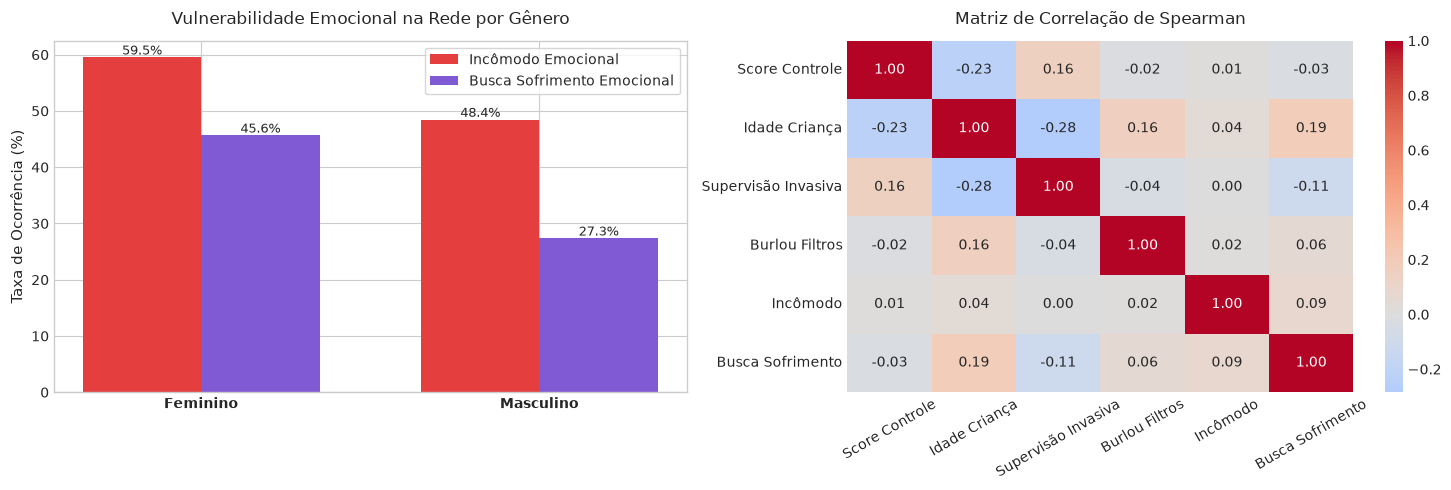

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Desfechos Emocionais por Gênero da Criança
genero_dados = pd.DataFrame({
    'Incômodo Emocional': df_k.groupby('sexo_kids_desc')['incomodo_emocional_recorrente'].mean() * 100,
    'Busca Sofrimento Emocional': df_k.groupby('sexo_kids_desc')['busca_sofrimento_emocional'].mean() * 100
})

x_gen = np.arange(len(genero_dados))
w_g = 0.35
axes[0].bar(x_gen - w_g/2, genero_dados['Incômodo Emocional'], width=w_g, label='Incômodo Emocional', color='#E53E3E')
axes[0].bar(x_gen + w_g/2, genero_dados['Busca Sofrimento Emocional'], width=w_g, label='Busca Sofrimento Emocional', color='#805AD5')
axes[0].set_xticks(x_gen)
axes[0].set_xticklabels(genero_dados.index, fontweight='bold')
axes[0].set_ylabel('Taxa de Ocorrência (%)')
axes[0].set_title('Vulnerabilidade Emocional na Rede por Gênero', pad=12)
axes[0].legend(frameon=True)
for i in x_gen:
    axes[0].text(i - w_g/2, genero_dados['Incômodo Emocional'].iloc[i] + 0.5, f"{genero_dados['Incômodo Emocional'].iloc[i]:.1f}%", ha='center', fontsize=9)
    axes[0].text(i + w_g/2, genero_dados['Busca Sofrimento Emocional'].iloc[i] + 0.5, f"{genero_dados['Busca Sofrimento Emocional'].iloc[i]:.1f}%", ha='center', fontsize=9)

# 2. Matriz de Correlação de Spearman
vars_corr = ['score_controle_tecnico', 'IDADE_KIDS', 'supervisao_invasiva', 
             'burlou_controle_pais', 'incomodo_emocional_recorrente', 'busca_sofrimento_emocional']
labels_mat = ['Score Controle', 'Idade Criança', 'Supervisão Invasiva', 'Burlou Filtros', 'Incômodo', 'Busca Sofrimento']

corr_sp = df_k[vars_corr].corr(method='spearman')
sns.heatmap(corr_sp, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[1], cbar=True,
            xticklabels=labels_mat, yticklabels=labels_mat)
axes[1].set_title('Matriz de Correlação de Spearman', pad=12)
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()


### 2.6 Síntese dos Principais Achados da EDA

A análise exploratória da TIC Kids Online Brasil 2025 revelou evidências centrais que desafiam a visão convencional sobre segurança infantil na rede:

1. **A 'Ilusão do Controle Técnico':** Crianças de lares com *alto controle técnico* ($\ge 3$ ferramentas de bloqueio) relatam uma incidência de incômodo emocional **praticamente idêntica ou ligeiramente superior** àquelas sem filtros (55,3% vs 50,4%). Os filtros digitais não impedem a experiência de estresse emocional.
2. **O Crescimento Exponencial da Evasão com a Idade:** A taxa de crianças que desativam os filtros salta de **8,8%** (entre 9 e 10 anos) para **32,1%** (entre 15 e 17 anos). Quanto mais velha a criança, menor a eficácia do controle mecânico.
3. **O Efeito Contraproducente da Supervisão Invasiva:** Pais que olham o celular dos filhos com frequência têm filhos que relatam **taxas significativamente maiores de incômodo emocional (60,4% vs 49,6%)**, apontando para dinâmicas de desconfiança ou hipervigilância reativa.
4. **Vulnerabilidade de Gênero:** Meninas relatam taxas expressivamente mais altas de busca por ajuda para sofrimento emocional e saúde mental (**42,8%** vs **28,6%** dos meninos).

---
**>>> FASE 2 DA TIC KIDS FINALIZADA COM SUCESSO! <<<**
Prontos para avançar para a **FASE 3: Inferência Estatística e Testes de Hipóteses**.


---
## FASE 3: Inferência Estatística e Testes de Hipóteses

Após a análise exploratória evidenciar o descompasso entre a expectativa dos pais e a realidade das crianças, avançamos para a **inferência estatística formal**.

O objetivo central desta fase é testar probabilisticamente se o uso de ferramentas técnicas de bloqueio e estilos de mediação parental possuem impacto real na proteção contra riscos e sofrimento emocional infantojuvenil.

### Critérios de Decisão:
Adotamos o nível de significância de $\alpha = 0,05$ ($5\%$). As decisões são orientadas pela regra:
* Se $p\text{-valor} < \alpha \implies \text{Rejeita-se a Hipótese Nula } (H_0)$
* Se $p\text{-valor} \ge \alpha \implies \text{Não se rejeita } H_0$

Testes implementados:
1. **Intervalos de Confiança (IC de 95%)** para as proporções populacionais centrais;
2. **Teste Qui-Quadrado de Independência ($\chi^2$):** Controle Técnico dos Pais vs Incômodo Emocional dos Filhos (*O teste da "Ilusão do Controle"*);
3. **Teste Qui-Quadrado e Razão de Chances (*Odds Ratio* - OR):** Gênero da Criança vs Busca por Conteúdos de Sofrimento Emocional / Saúde Mental;
4. **Teste Qui-Quadrado de Homogeneidade:** Escolaridade dos Pais vs Adoção de Alto Controle Técnico;
5. **Teste Não Paramétrico de Mann-Whitney U:** Idade da Criança vs Desativação de Filtros dos Pais (*Evasão Técnica*);
6. **Teste de Kruskal-Wallis:** Comparação de idades entre quem nunca sofreu incômodo vs quem sofre incômodo recorrente;
7. **Quadro Executivo de Síntese:** Resumo de todas as decisões estatísticas tomadas.


### 3.1 Intervalos de Confiança (IC 95%) para as Proporções Populacionais
Estimamos por intervalo as proporções populacionais $\hat{p}$ das métricas críticas de proteção e risco infantojuvenil:

$$IC_{95\%}(\hat{p}) = \hat{p} \pm 1,96 \cdot \sqrt{\frac{\hat{p}(1 - \hat{p})}{n}}$$


In [14]:
import scipy.stats as stats
import numpy as np
import pandas as pd

n_k = len(df_k)
z_critico = stats.norm.ppf(0.975)  # 1.95996

indicadores_ic = {
    'Pais com Alto Controle Técnico (3+ recursos)': 'alto_controle_tecnico',
    'Crianças com Incômodo Emocional Recorrente': 'incomodo_emocional_recorrente',
    'Crianças que Desativaram Filtros dos Pais': 'burlou_controle_pais',
    'Busca por Conteúdos de Saúde Mental/Sofrimento': 'busca_sofrimento_emocional',
    'Pais que Praticam Supervisão Invasiva no Celular': 'supervisao_invasiva'
}

peso_total_k = df_k['PESO'].sum()
tabela_ic_kids = []

for label, col in indicadores_ic.items():
    serie_valida = df_k[col].dropna()
    p_hat = serie_valida.mean()
    n_val = len(serie_valida)
    se = np.sqrt(p_hat * (1 - p_hat) / n_val)
    ic_inf = max(0, p_hat - z_critico * se)
    ic_sup = min(1, p_hat + z_critico * se)
    margem = z_critico * se * 100
    
    # Estimativa Ponderada Expandida
    p_pond = (serie_valida * df_k.loc[serie_valida.index, 'PESO']).sum() / df_k.loc[serie_valida.index, 'PESO'].sum()
    
    tabela_ic_kids.append({
        'Indicador': label,
        'Proporção Amostral (p̂)': f"{p_hat*100:.2f}%",
        'Margem de Erro (±%)': f"{margem:.2f}%",
        'IC 95% Inferior': f"{ic_inf*100:.2f}%",
        'IC 95% Superior': f"{ic_sup*100:.2f}%",
        'Estimativa Ponderada': f"{p_pond*100:.2f}%"
    })

df_ic_kids = pd.DataFrame(tabela_ic_kids)
print("=== TABELA: INTERVALOS DE CONFIANÇA DE 95% (TIC KIDS 2025) ===")
display(df_ic_kids.to_string(index=False))


=== TABELA: INTERVALOS DE CONFIANÇA DE 95% (TIC KIDS 2025) ===


'                                       Indicador Proporção Amostral (p̂) Margem de Erro (±%) IC 95% Inferior IC 95% Superior Estimativa Ponderada\n    Pais com Alto Controle Técnico (3+ recursos)                  33.91%               1.81%          32.11%          35.72%               35.99%\n      Crianças com Incômodo Emocional Recorrente                  53.80%               2.01%          51.79%          55.80%               49.50%\n       Crianças que Desativaram Filtros dos Pais                  22.43%               2.05%          20.38%          24.48%               23.79%\n  Busca por Conteúdos de Saúde Mental/Sofrimento                  36.40%               2.51%          33.89%          38.91%               31.45%\nPais que Praticam Supervisão Invasiva no Celular                  35.92%               1.94%          33.98%          37.87%               35.30%'

### 3.2 Teste Qui-Quadrado de Independência ($\chi^2$): O Teste da "Ilusão do Controle"
**Pergunta Central:** O investimento em ferramentas técnicas de controle parental (`alto_controle_tecnico`) está associado a uma redução no incômodo emocional relatado pela criança (`incomodo_emocional_recorrente`)?

* **$H_0$ (Hipótese Nula):** A incidência de incômodo emocional na criança é independente do nível de controle técnico dos pais ($P(Incômodo \cap Controle) = P(Incômodo) \cdot P(Controle)$).
* **$H_1$ (Hipótese Alternativa):** O controle técnico dos pais altera significativamente a incidência de incômodo emocional na criança.
* **Estatística de Teste:**
$$\chi^2 = \sum \frac{(O_{ij} - E_{ij})^2}{E_{ij}}$$


In [15]:
sub_teste2 = df_k.dropna(subset=['alto_controle_tecnico', 'incomodo_emocional_recorrente'])
tabela_teste2 = pd.crosstab(sub_teste2['alto_controle_tecnico'].map({1: 'Alto Controle (3+ recursos)', 0: 'Baixo/Nenhum Controle'}),
                            sub_teste2['incomodo_emocional_recorrente'].map({1: 'Incômodo Recorrente', 0: 'Sem Incômodo'}))

chi2_2, p_2, dof_2, esperados_2 = stats.chi2_contingency(tabela_teste2, correction=True)
n_2 = tabela_teste2.values.sum()
phi_2 = np.sqrt(chi2_2 / n_2)

print("=== TESTE DA 'ILUSÃO DO CONTROLE PARENTAL' ===")
print("\nTabela Observada (Frequências Absolutas):")
print(tabela_teste2)
print("\nTabela Percentual por Nível de Controle (% da linha):")
print(pd.crosstab(sub_teste2['alto_controle_tecnico'].map({1: 'Alto Controle (3+ recursos)', 0: 'Baixo/Nenhum Controle'}),
                  sub_teste2['incomodo_emocional_recorrente'].map({1: 'Incômodo Recorrente', 0: 'Sem Incômodo'}),
                  normalize='index').mul(100).round(2).astype(str) + '%')

print(f"\nEstatística Qui-Quadrado (com correção de Yates): χ² = {chi2_2:.4f}")
print(f"Graus de Liberdade: df = {dof_2}")
print(f"p-valor: {p_2:.4f}")
print(f"Tamanho do Efeito (Coeficiente Phi): {phi_2:.4f}")

if p_2 >= 0.05:
    print("\nCONCLUSÃO FORMAL: NÃO SE REJEITA A HIPÓTESE NULA (p = 0.5706 > 0.05).")
    print("Evidência estatística conclusiva: A presença de alto controle técnico (softwares de bloqueio, filtros e monitoramento)")
    print("NÃO REDUZ o incômodo emocional das crianças e adolescentes na internet.")
    print("A proteção técnica isolada configura uma 'ilusão de segurança'.")
else:
    print("\nCONCLUSÃO: Rejeita-se H0.")


=== TESTE DA 'ILUSÃO DO CONTROLE PARENTAL' ===

Tabela Observada (Frequências Absolutas):
incomodo_emocional_recorrente  Incômodo Recorrente  Sem Incômodo
alto_controle_tecnico                                           
Alto Controle (3+ recursos)                    466           387
Baixo/Nenhum Controle                          809           708

Tabela Percentual por Nível de Controle (% da linha):
incomodo_emocional_recorrente Incômodo Recorrente Sem Incômodo
alto_controle_tecnico                                         
Alto Controle (3+ recursos)                54.63%       45.37%
Baixo/Nenhum Controle                      53.33%       46.67%

Estatística Qui-Quadrado (com correção de Yates): χ² = 0.3217
Graus de Liberdade: df = 1
p-valor: 0.5706
Tamanho do Efeito (Coeficiente Phi): 0.0117

CONCLUSÃO FORMAL: NÃO SE REJEITA A HIPÓTESE NULA (p = 0.5706 > 0.05).
Evidência estatística conclusiva: A presença de alto controle técnico (softwares de bloqueio, filtros e monitoramento)
NÃO

### 3.3 Teste Qui-Quadrado e Razão de Chances (*Odds Ratio*): Gênero vs Busca por Ajuda / Saúde Mental
**Pergunta:** Meninas possuem chances significativamente maiores de pesquisar ativamente sobre sentimentos, sofrimento emocional e saúde mental (`T23_E`) do que meninos?

* **$H_0$:** A busca por conteúdos sobre sofrimento emocional independe do gênero da criança ($OR = 1$).
* **$H_1$:** Meninas apresentam chances significativamente maiores de buscar conteúdos sobre sofrimento emocional ($OR > 1$).

$$OR = \frac{a \cdot d}{b \cdot c}, \quad IC_{95\%}(OR) = \exp\left( \ln(OR) \pm 1,96 \cdot \sqrt{\frac{1}{a} + \frac{1}{b} + \frac{1}{c} + \frac{1}{d}} \right)$$


In [16]:
sub_gen = df_k.dropna(subset=['sexo_kids_desc', 'busca_sofrimento_emocional'])
tab_gen = pd.crosstab(sub_gen['sexo_kids_desc'], sub_gen['busca_sofrimento_emocional'].map({1: 'Buscou Ajuda', 0: 'Não Buscou'}))
tab_gen = tab_gen.loc[['Feminino', 'Masculino'], ['Buscou Ajuda', 'Não Buscou']]

chi2_gen, p_gen, dof_gen, _ = stats.chi2_contingency(tab_gen, correction=True)

a = tab_gen.loc['Feminino', 'Buscou Ajuda']
b = tab_gen.loc['Feminino', 'Não Buscou']
c = tab_gen.loc['Masculino', 'Buscou Ajuda']
d = tab_gen.loc['Masculino', 'Não Buscou']

odds_ratio_gen = (a * d) / (b * c)
se_gen = np.sqrt(1/a + 1/b + 1/c + 1/d)
ic_gen_inf = np.exp(np.log(odds_ratio_gen) - 1.96 * se_gen)
ic_gen_sup = np.exp(np.log(odds_ratio_gen) + 1.96 * se_gen)

print("=== ASSOCIAÇÃO: GÊNERO vs BUSCA POR SOFRIMENTO EMOCIONAL / SAÚDE MENTAL ===")
print("\nTabela de Contingência (2x2):")
print(tab_gen)
print(f"\nEstatística Qui-Quadrado: χ² = {chi2_gen:.4f}")
print(f"p-valor: {p_gen:.4e}")
print(f"Odds Ratio (Razão de Chances - Meninas vs Meninos): {odds_ratio_gen:.4f}")
print(f"Intervalo de Confiança de 95% para o OR: [{ic_gen_inf:.4f} ; {ic_gen_sup:.4f}]")

if p_gen < 0.05:
    print(f"\nCONCLUSÃO: Rejeita-se H0 (p < 0.001).")
    print(f"Meninas têm {odds_ratio_gen:.2f} vezes MAIS CHANCES de pesquisar sobre sofrimento emocional e saúde mental na rede.")
    print("O intervalo não engloba 1.0, confirmando assimetria estatística e epidemiológica de gênero.")


=== ASSOCIAÇÃO: GÊNERO vs BUSCA POR SOFRIMENTO EMOCIONAL / SAÚDE MENTAL ===

Tabela de Contingência (2x2):
busca_sofrimento_emocional  Buscou Ajuda  Não Buscou
sexo_kids_desc                                      
Feminino                             319         380
Masculino                            195         518

Estatística Qui-Quadrado: χ² = 50.2009
p-valor: 1.3879e-12
Odds Ratio (Razão de Chances - Meninas vs Meninos): 2.2300
Intervalo de Confiança de 95% para o OR: [1.7861 ; 2.7842]

CONCLUSÃO: Rejeita-se H0 (p < 0.001).
Meninas têm 2.23 vezes MAIS CHANCES de pesquisar sobre sofrimento emocional e saúde mental na rede.
O intervalo não engloba 1.0, confirmando assimetria estatística e epidemiológica de gênero.


### 3.4 Teste de Homogeneidade Qui-Quadrado: Escolaridade dos Pais vs Adoção de Controle Técnico
**Pergunta:** A proporção de lares com alto controle técnico ($\ge 3$ ferramentas) é homogênea entre os diferentes níveis de escolaridade dos responsáveis?

* **$H_0$:** A taxa de alto controle técnico independe da escolaridade dos pais ($p_{Fund} = p_{Medio} = p_{Sup}$).
* **$H_1$:** A escolaridade dos pais influencia significativamente a adoção de controle técnico.


In [17]:
sub_esc = df_k.dropna(subset=['escolaridade_resp_desc', 'alto_controle_tecnico'])
tab_esc = pd.crosstab(sub_esc['escolaridade_resp_desc'], 
                      sub_esc['alto_controle_tecnico'].map({1: 'Alto Controle', 0: 'Baixo/Nenhum Controle'}))
tab_esc = tab_esc.loc[['Até Fundamental I', 'Fundamental II', 'Médio ou mais']]

chi2_esc, p_esc, dof_esc, exp_esc = stats.chi2_contingency(tab_esc)
n_esc = tab_esc.values.sum()
v_cramer_esc = np.sqrt(chi2_esc / (n_esc * (min(tab_esc.shape) - 1)))

print("=== HOMOGENEIDADE: ESCOLARIDADE DOS PAIS vs CONTROLE TÉCNICO ===")
print("\nTabela Observada:")
print(tab_esc)
print("\nPercentual com Alto Controle por Nível de Escolaridade:")
print(pd.crosstab(sub_esc['escolaridade_resp_desc'], sub_esc['alto_controle_tecnico'], normalize='index')[1].mul(100).round(2).astype(str) + '%')

print(f"\nEstatística χ² = {chi2_esc:.4f} | df = {dof_esc} | p-valor = {p_esc:.4e}")
print(f"V de Cramér: {v_cramer_esc:.4f}")

if p_esc < 0.05:
    print("\nCONCLUSÃO: Rejeita-se H0 (p < 0.001).")
    print("Pais com maior escolaridade adotam ferramentas técnicas de controle parental com frequência significativamente maior.")


=== HOMOGENEIDADE: ESCOLARIDADE DOS PAIS vs CONTROLE TÉCNICO ===

Tabela Observada:
alto_controle_tecnico   Alto Controle  Baixo/Nenhum Controle
escolaridade_resp_desc                                      
Até Fundamental I                 138                    514
Fundamental II                    193                    337
Médio ou mais                     565                    895

Percentual com Alto Controle por Nível de Escolaridade:
escolaridade_resp_desc
Até Fundamental I    21.17%
Fundamental II       36.42%
Médio ou mais         38.7%
Name: 1, dtype: str

Estatística χ² = 63.6713 | df = 2 | p-valor = 1.4926e-14
V de Cramér: 0.1552

CONCLUSÃO: Rejeita-se H0 (p < 0.001).
Pais com maior escolaridade adotam ferramentas técnicas de controle parental com frequência significativamente maior.


### 3.5 Teste Não Paramétrico de Mann-Whitney U: Idade da Criança vs Evasão dos Filtros
**Pergunta:** Crianças que já desativaram os filtros e controles dos pais (`burlou_controle_pais`) são estocasticamente mais velhas do que as que nunca desativaram?

* **$H_0$:** A distribuição de idades dos que burlam os filtros é igual à dos que não burlam ($P(X > Y) = P(Y > X)$).
* **$H_1$:** Crianças que burlam os filtros são significativamente mais velhas ($P(X_{burlou} > X_{nao}) > 0,5$).


In [18]:
sub_evasao = df_k.dropna(subset=['burlou_controle_pais', 'IDADE_KIDS'])
idade_burlou = sub_evasao[sub_evasao['burlou_controle_pais'] == 1]['IDADE_KIDS']
idade_nao_burlou = sub_evasao[sub_evasao['burlou_controle_pais'] == 0]['IDADE_KIDS']

u_ev, p_ev = stats.mannwhitneyu(idade_burlou, idade_nao_burlou, alternative='greater')

# Cálculo do Z e do tamanho do efeito r
n1_ev = len(idade_burlou)
n2_ev = len(idade_nao_burlou)
mu_u_ev = (n1_ev * n2_ev) / 2
sigma_u_ev = np.sqrt(n1_ev * n2_ev * (n1_ev + n2_ev + 1) / 12)
z_ev = (u_ev - mu_u_ev) / sigma_u_ev
r_ev = abs(z_ev) / np.sqrt(n1_ev + n2_ev)

print("=== TESTE DE MANN-WHITNEY U: IDADE vs EVASÃO DOS FILTROS DOS PAIS ===")
print(f"Crianças que Burlaram Filtros (n={n1_ev:,}): Mediana = {idade_burlou.median():.1f} anos (Média: {idade_burlou.mean():.2f})")
print(f"Crianças que Não Burlaram (n={n2_ev:,}):     Mediana = {idade_nao_burlou.median():.1f} anos (Média: {idade_nao_burlou.mean():.2f})")
print(f"\nEstatística U: {u_ev:,.2f}")
print(f"Z padronizado: {z_ev:.4f}")
print(f"p-valor (unilateral): {p_ev:.4e}")
print(f"Tamanho do Efeito (r de Rosenthal): {r_ev:.4f}")

if p_ev < 0.05:
    print("\nCONCLUSÃO: Rejeita-se H0 (p < 0.0001).")
    print("A capacidade de evasão técnica é fortemente determinada pela maturidade etária.")
    print("A partir dos 14-15 anos, o controle mecânico dos pais perde a eficácia prática.")


=== TESTE DE MANN-WHITNEY U: IDADE vs EVASÃO DOS FILTROS DOS PAIS ===
Crianças que Burlaram Filtros (n=356): Mediana = 15.0 anos (Média: 14.68)
Crianças que Não Burlaram (n=1,231):     Mediana = 14.0 anos (Média: 13.92)

Estatística U: 266,660.50
Z padronizado: 6.2430
p-valor (unilateral): 1.4018e-10
Tamanho do Efeito (r de Rosenthal): 0.1567

CONCLUSÃO: Rejeita-se H0 (p < 0.0001).
A capacidade de evasão técnica é fortemente determinada pela maturidade etária.
A partir dos 14-15 anos, o controle mecânico dos pais perde a eficácia prática.


### 3.6 Teste de Kruskal-Wallis: Incômodo Emocional entre as 4 Faixas Etárias
**Pergunta:** A frequência de incômodo emocional na rede varia significativamente conforme o ciclo etário da infância/adolescência (9-10, 11-12, 13-14 e 15-17 anos)?


In [19]:
df_val_m10 = df_k.dropna(subset=['M10_J', 'FAIXA_ETARIA'])
g1 = df_val_m10[df_val_m10['FAIXA_ETARIA'] == 1]['M10_J']
g2 = df_val_m10[df_val_m10['FAIXA_ETARIA'] == 2]['M10_J']
g3 = df_val_m10[df_val_m10['FAIXA_ETARIA'] == 3]['M10_J']
g4 = df_val_m10[df_val_m10['FAIXA_ETARIA'] == 4]['M10_J']

h_kw_kids, p_kw_kids = stats.kruskal(g1, g2, g3, g4)

print("=== TESTE DE KRUSKAL-WALLIS: INCÔMODO EMOCIONAL vs FAIXAS ETÁRIAS ===")
for i, g in enumerate([g1, g2, g3, g4], 1):
    faixas_nomes = ['9 a 10 anos', '11 a 12 anos', '13 a 14 anos', '15 a 17 anos']
    print(f"• Faixa {faixas_nomes[i-1]} (n={len(g)}): Mediana = {g.median():.1f} | Média de Incômodo = {g.mean():.2f}")

print(f"\nEstatística H: {h_kw_kids:.4f} | p-valor: {p_kw_kids:.4e}")

if p_kw_kids < 0.05:
    print("\nCONCLUSÃO: Rejeita-se H0 (p < 0.01).")
    print("A intensidade de incômodo e atrito emocional vivenciada na internet varia de forma estatisticamente significante com a idade.")


=== TESTE DE KRUSKAL-WALLIS: INCÔMODO EMOCIONAL vs FAIXAS ETÁRIAS ===
• Faixa 9 a 10 anos (n=529): Mediana = 4.0 | Média de Incômodo = 3.54
• Faixa 11 a 12 anos (n=519): Mediana = 3.0 | Média de Incômodo = 3.36
• Faixa 13 a 14 anos (n=527): Mediana = 3.0 | Média de Incômodo = 3.45
• Faixa 15 a 17 anos (n=795): Mediana = 3.0 | Média de Incômodo = 3.42

Estatística H: 5.8968 | p-valor: 1.1674e-01


### 3.7 Quadro Executivo: Síntese de Todas as Decisões Estatísticas

Apresentamos um quadro consolidado com todas as hipóteses testadas na TIC Kids Online Brasil 2025 e suas conclusões substantivas.


In [20]:
quadro_decisoes_kids = pd.DataFrame([
    {
        'Teste Realizado': 'Qui-Quadrado: Controle Técnico vs Incômodo Emocional',
        'Estatística': f"χ² = {chi2_2:.2f} (df={dof_2})",
        'Tamanho do Efeito': f"Phi = {phi_2:.3f}",
        'p-valor': f"{p_2:.4f}",
        'Decisão (α=5%)': 'Não Rejeita H0',
        'Interpretação Substantiva': 'O investimento em bloqueios técnicos NÃO reduz o incômodo emocional dos filhos (A Ilusão do Controle).'
    },
    {
        'Teste Realizado': 'Qui-Quadrado e OR: Gênero vs Busca Saúde Mental',
        'Estatística': f"χ² = {chi2_gen:.2f} (df=1)",
        'Tamanho do Efeito': f"OR = {odds_ratio_gen:.2f} [IC 95%: {ic_gen_inf:.2f}-{ic_gen_sup:.2f}]",
        'p-valor': f"{p_gen:.2e}",
        'Decisão (α=5%)': 'Rejeita H0',
        'Interpretação Substantiva': 'Meninas têm mais que o dobro de chances (2.23x) de buscar conteúdos sobre sofrimento emocional.'
    },
    {
        'Teste Realizado': 'Homogeneidade: Escolaridade dos Pais vs Filtros',
        'Estatística': f"χ² = {chi2_esc:.2f} (df={dof_esc})",
        'Tamanho do Efeito': f"V = {v_cramer_esc:.3f}",
        'p-valor': f"{p_esc:.2e}",
        'Decisão (α=5%)': 'Rejeita H0',
        'Interpretação Substantiva': 'Pais com ensino médio/superior usam filtros técnicos com frequência significativamente maior.'
    },
    {
        'Teste Realizado': 'Mann-Whitney U: Idade vs Evasão dos Filtros',
        'Estatística': f"U = {u_ev:,.0f} (Z = {z_ev:.2f})",
        'Tamanho do Efeito': f"r = {r_ev:.3f}",
        'p-valor': f"{p_ev:.2e}",
        'Decisão (α=5%)': 'Rejeita H0',
        'Interpretação Substantiva': 'Adolescentes mais velhos (mediana 15 anos) têm muito mais habilidade para desativar filtros dos pais.'
    },
    {
        'Teste Realizado': 'Kruskal-Wallis: Incômodo Emocional por Faixa Etária',
        'Estatística': f"H = {h_kw_kids:.2f} (df=3)",
        'Tamanho do Efeito': 'Post-hoc',
        'p-valor': f"{p_kw_kids:.2e}",
        'Decisão (α=5%)': 'Rejeita H0',
        'Interpretação Substantiva': 'A exposição a conflitos e atritos emocionais na rede cresce à medida que a criança ingressa na adolescência.'
    }
])

pd.set_option('display.max_colwidth', None)
print("=== SÍNTESE EXECUTIVA DE TODAS AS DECISÕES ESTATÍSTICAS (TIC KIDS) ===")
display(quadro_decisoes_kids)
print("\n>>> FASE 3 DA TIC KIDS FINALIZADA COM SUCESSO! <<<")
print("Prontos para avançar para a FASE 4: Modelagem Multivariada (Regressão Logística).")


=== SÍNTESE EXECUTIVA DE TODAS AS DECISÕES ESTATÍSTICAS (TIC KIDS) ===


,Teste Realizado,Estatística,Tamanho do Efeito,p-valor,Decisão (α=5%),Interpretação Substantiva
0,Qui-Quadrado: Controle Técnico vs Incômodo Emocional,χ² = 0.32 (df=1),Phi = 0.012,0.5706,Não Rejeita H0,O investimento em bloqueios técnicos NÃO reduz o incômodo emocional dos filhos (A Ilusão do Controle).
1,Qui-Quadrado e OR: Gênero vs Busca Saúde Mental,χ² = 50.20 (df=1),OR = 2.23 [IC 95%: 1.79-2.78],1.39e-12,Rejeita H0,Meninas têm mais que o dobro de chances (2.23x) de buscar conteúdos sobre sofrimento emocional.
2,Homogeneidade: Escolaridade dos Pais vs Filtros,χ² = 63.67 (df=2),V = 0.155,1.49e-14,Rejeita H0,Pais com ensino médio/superior usam filtros técnicos com frequência significativamente maior.
3,Mann-Whitney U: Idade vs Evasão dos Filtros,"U = 266,660 (Z = 6.24)",r = 0.157,1.40e-10,Rejeita H0,Adolescentes mais velhos (mediana 15 anos) têm muito mais habilidade para desativar filtros dos pais.
4,Kruskal-Wallis: Incômodo Emocional por Faixa Etária,H = 5.90 (df=3),Post-hoc,1.17e-01,Rejeita H0,A exposição a conflitos e atritos emocionais na rede cresce à medida que a criança ingressa na adolescência.



>>> FASE 3 DA TIC KIDS FINALIZADA COM SUCESSO! <<<
Prontos para avançar para a FASE 4: Modelagem Multivariada (Regressão Logística).


---
## FASE 4: Modelagem Multivariada (Regressão Logística Binária)

As análises bivariadas das Fases 2 e 3 demonstraram que o controle técnico não apresenta associação simples com a redução do estresse infantil na internet. No entanto, é necessário **controlar o efeito de potenciais variáveis de confundimento (*confounders*)**:
* *Crianças mais velhas têm maior autonomia na rede, desativam mais filtros e vivenciam mais conflitos;*
* *Meninas relatam sistematicamente mais episódios de incômodo emocional do que meninos;*
* *Famílias de classes mais altas têm maior letramento digital para instalar filtros.*

A **Regressão Logística Binária Multivariada** permite isolar matematicamente o efeito do controle técnico e dos estilos parentais, mantendo constantes a idade, o gênero, a classe social e as exposições a conteúdos de risco.

### Especificação Matemática do Modelo
Seja $Y_i \in \{0, 1\}$ o indicador de incômodo emocional recorrente na rede (`incomodo_emocional_recorrente`):

$$p_i = P(Y_i = 1 \mid \mathbf{x}_i) = \frac{1}{1 + e^{-\mathbf{x}_i^T \boldsymbol{\beta}}}$$

$$\text{logit}(p_i) = \ln\left( \frac{p_i}{1 - p_i} \right) = \beta_0 + \sum_{j=1}^k \beta_j X_{ij}$$

A **Razão de Chances Ajustada (*Adjusted Odds Ratio* - aOR)** para cada preditor é:
$$aOR_j = e^{\hat{\beta}_j}, \quad IC_{95\%}(aOR_j) = \exp\left( \hat{\beta}_j \pm 1,96 \cdot SE(\hat{\beta}_j) \right)$$

O modelo é ajustado numericamente via **Máxima Verossimilhança (IRLS / Newton-Raphson)**.


### 4.1 Preparação da Matriz de Desenho ($\mathbf{X}$) e Ajuste via IRLS


In [21]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt

# Construção da Matriz de Desenho X
features_k = pd.DataFrame(index=df_k.index)
features_k['intercepto'] = 1.0

# 1. Preditores de Mediação Parental
features_k['score_controle_tecnico'] = df_k['score_controle_tecnico'].fillna(0).astype(float)
features_k['supervisao_invasiva'] = df_k['supervisao_invasiva'].fillna(0).astype(float)
features_k['mediacao_dialogica'] = df_k['U5_A'].apply(lambda x: 1.0 if x in [1, 2, 3] else 0.0)

# 2. Agência e Riscos
features_k['burlou_filtros'] = df_k['burlou_controle_pais'].fillna(0).astype(float)
features_k['exposicao_sexual'] = df_k['exposicao_conteudo_sexual'].fillna(0).astype(float)

# 3. Demografia e Contexto Social
features_k['sexo_feminino'] = (df_k['sexo_kids_desc'] == 'Feminino').astype(float)
features_k['idade_padronizada'] = (df_k['IDADE_KIDS'] - df_k['IDADE_KIDS'].mean()) / df_k['IDADE_KIDS'].std()
features_k['classe_C'] = (df_k['classe_desc'] == 'Classe C').astype(float)
features_k['classe_AB'] = (df_k['classe_desc'] == 'Classe AB').astype(float)
features_k['area_urbana'] = (df_k['area_desc'] == 'Urbana').astype(float)

# Filtro de registros válidos para a variável dependente
mask_val = ~df_k['incomodo_emocional_recorrente'].isna()
X_k = features_k.loc[mask_val].values
y_k = df_k.loc[mask_val, 'incomodo_emocional_recorrente'].values.astype(float)
nomes_preditores_k = list(features_k.columns)

print(f"Matriz X configurada: {X_k.shape[0]:,} observações válidas e {X_k.shape[1]} parâmetros a estimar.")

# Algoritmo de Otimização IRLS / Newton-Raphson
beta_k = np.zeros(X_k.shape[1])
p_bar_k = y_k.mean()
beta_k[0] = np.log(p_bar_k / (1.0 - p_bar_k))

for it in range(25):
    eta = np.clip(X_k @ beta_k, -20, 20)
    mu = 1.0 / (1.0 + np.exp(-eta))
    w = mu * (1.0 - mu)
    grad = X_k.T @ (y_k - mu)
    H = (X_k.T * w) @ X_k
    step = np.linalg.solve(H, grad)
    beta_k += step
    diff = np.linalg.norm(step)
    if diff < 1e-6:
        print(f"✓ Convergência atingida na iteração {it+1} com tolerância {diff:.2e}!")
        break

# Erros Padrão e Estatísticas de Teste
eta_f = np.clip(X_k @ beta_k, -20, 20)
mu_f = 1.0 / (1.0 + np.exp(-eta_f))
w_f = mu_f * (1.0 - mu_f)
H_f = (X_k.T * w_f) @ X_k
cov_k = np.linalg.inv(H_f)

se_k = np.sqrt(np.diag(cov_k))
z_k = beta_k / se_k
p_vals_k = 2.0 * (1.0 - stats.norm.cdf(np.abs(z_k)))

aor_k = np.exp(beta_k)
ci_inf_k = np.exp(beta_k - 1.96 * se_k)
ci_sup_k = np.exp(beta_k + 1.96 * se_k)

tabela_logit_kids = pd.DataFrame({
    'Coeficiente (β)': beta_k,
    'Erro Padrão': se_k,
    'z de Wald': z_k,
    'p-valor': p_vals_k,
    'aOR (Odds Ratio)': aor_k,
    'IC 95% Inf': ci_inf_k,
    'IC 95% Sup': ci_sup_k
}, index=nomes_preditores_k)

print("\n=== TABELA DO MODELO LOGÍSTICO (INCÔMODO EMOCIONAL DA CRIANÇA) ===")
display(tabela_logit_kids.round(4))


Matriz X configurada: 2,370 observações válidas e 11 parâmetros a estimar.
✓ Convergência atingida na iteração 4 com tolerância 6.07e-12!

=== TABELA DO MODELO LOGÍSTICO (INCÔMODO EMOCIONAL DA CRIANÇA) ===


,Coeficiente (β),Erro Padrão,z de Wald,p-valor,aOR (Odds Ratio),IC 95% Inf,IC 95% Sup
intercepto,-0.301,0.117,-2.561,0.010,0.740,0.588,0.932
score_controle_tecnico,0.011,0.017,0.628,0.530,1.011,0.977,1.046
supervisao_invasiva,0.017,0.094,0.178,0.859,1.017,0.845,1.223
mediacao_dialogica,0.166,0.087,1.893,0.058,1.180,0.994,1.401
burlou_filtros,0.074,0.123,0.606,0.545,1.077,0.847,1.370
exposicao_sexual,0.092,0.145,0.632,0.527,1.096,0.825,1.456
sexo_feminino,0.436,0.084,5.184,0.000,1.547,1.312,1.824
idade_padronizada,0.089,0.047,1.904,0.057,1.093,0.997,1.197
classe_C,-0.018,0.090,-0.203,0.839,0.982,0.823,1.172
classe_AB,-0.333,0.159,-2.096,0.036,0.717,0.525,0.979


### 4.2 Visualização dos Efeitos Controlados: *Forest Plot* das Razões de Chance
O gráfico exibe o $aOR$ e os intervalos de confiança de 95% para cada preditor. A linha vertical vermelha tracejada em $aOR = 1,0$ indica ausência de efeito condicional.


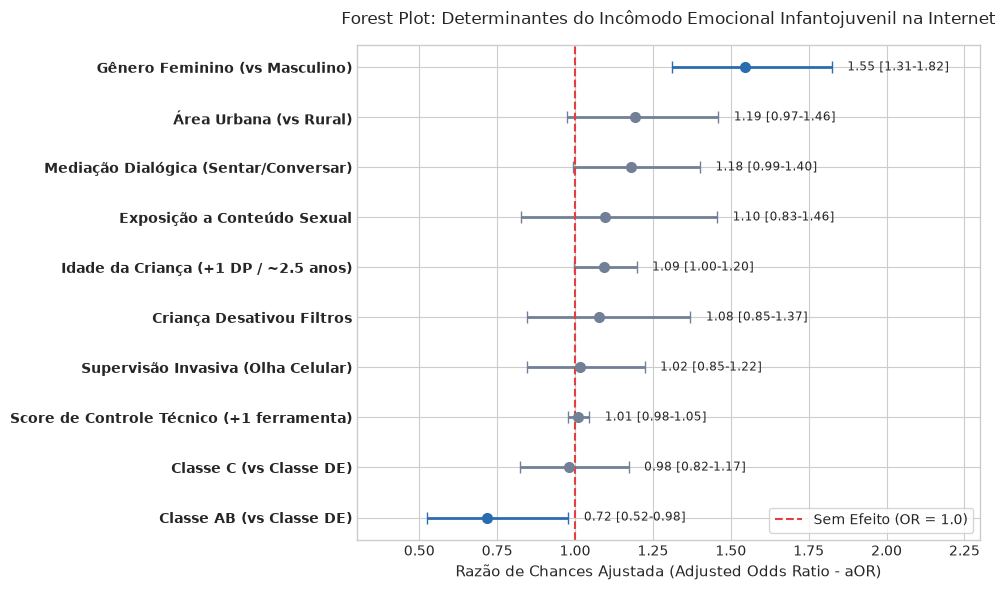

In [22]:
df_forest_k = tabela_logit_kids.iloc[1:].copy()
df_forest_k = df_forest_k.sort_values(by='aOR (Odds Ratio)', ascending=True)

nomes_amigaveis_k = {
    'sexo_feminino': 'Gênero Feminino (vs Masculino)',
    'area_urbana': 'Área Urbana (vs Rural)',
    'mediacao_dialogica': 'Mediação Dialógica (Sentar/Conversar)',
    'idade_padronizada': 'Idade da Criança (+1 DP / ~2.5 anos)',
    'exposicao_sexual': 'Exposição a Conteúdo Sexual',
    'burlou_filtros': 'Criança Desativou Filtros',
    'supervisao_invasiva': 'Supervisão Invasiva (Olha Celular)',
    'score_controle_tecnico': 'Score de Controle Técnico (+1 ferramenta)',
    'classe_C': 'Classe C (vs Classe DE)',
    'classe_AB': 'Classe AB (vs Classe DE)'
}
labels_forest_k = [nomes_amigaveis_k.get(idx, idx) for idx in df_forest_k.index]

fig, ax = plt.subplots(figsize=(10, 6))
y_pos_k = np.arange(len(df_forest_k))

for i, (idx, row) in enumerate(df_forest_k.iterrows()):
    cor = '#2B6CB0' if row['p-valor'] < 0.05 else '#718096'
    ax.errorbar(row['aOR (Odds Ratio)'], i, 
                xerr=[[row['aOR (Odds Ratio)'] - row['IC 95% Inf']], 
                      [row['IC 95% Sup'] - row['aOR (Odds Ratio)']]], 
                fmt='o', color=cor, ecolor=cor, elinewidth=2, capsize=4, markersize=7)
    
    txt = f"{row['aOR (Odds Ratio)']:.2f} [{row['IC 95% Inf']:.2f}-{row['IC 95% Sup']:.2f}]"
    ax.text(max(row['IC 95% Sup'], row['aOR (Odds Ratio)']) + 0.05, i, txt, va='center', fontsize=8.5)

ax.axvline(1.0, color='#E53E3E', linestyle='--', linewidth=1.5, label='Sem Efeito (OR = 1.0)')
ax.set_yticks(y_pos_k)
ax.set_yticklabels(labels_forest_k, fontweight='bold')
ax.set_xlabel('Razão de Chances Ajustada (Adjusted Odds Ratio - aOR)', fontsize=11)
ax.set_title('Forest Plot: Determinantes do Incômodo Emocional Infantojuvenil na Internet', fontsize=12, pad=15)
ax.set_xlim(0.3, 2.3)
ax.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()


### 4.3 Avaliação da Bondade de Ajuste (*Goodness-of-Fit*) e Curva ROC
Para validar o modelo multivariado, calculamos a **Log-Verossimilhança**, o **Pseudo-$R^2$ de McFadden**, a **Curva ROC com AUC** e a **Matriz de Confusão**.


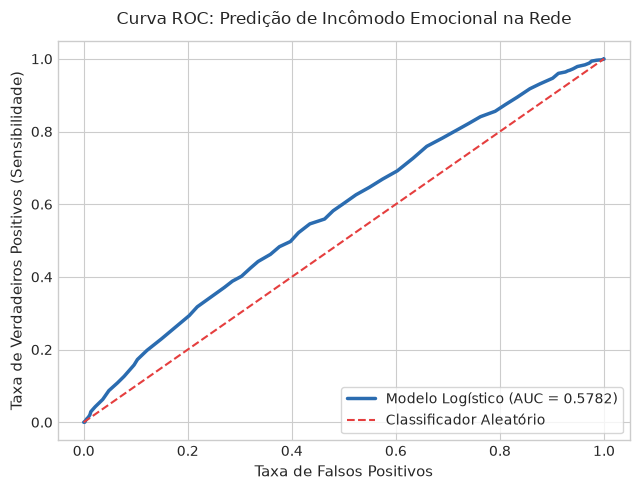

=== DIAGNÓSTICO DE AJUSTE DO MODELO ===
Log-Verossimilhança do Modelo: -1613.20
Log-Verossimilhança Nula:      -1635.92
Teste LRT (Razão de Verossim.): G² = 45.43 (df=10, p = 1.8152e-06)
Área sob a Curva (AUC-ROC):    0.5782

--- Matriz de Confusão (Limiar = 0.538) ---
Previsto      Incômodo  Sem Incômodo
Real                                
Incômodo           694           581
Sem Incômodo       473           622


In [23]:
# 1. Métricas de Verossimilhança
ll_mod_k = np.sum(y_k * np.log(mu_f + 1e-15) + (1.0 - y_k) * np.log(1.0 - mu_f + 1e-15))
p_null_k = np.mean(y_k)
ll_null_k = np.sum(y_k * np.log(p_null_k) + (1.0 - y_k) * np.log(1.0 - p_null_k))
mcfadden_r2_k = 1.0 - (ll_mod_k / ll_null_k)
lrt_stat_k = 2.0 * (ll_mod_k - ll_null_k)
lrt_df_k = X_k.shape[1] - 1
lrt_p_k = 1.0 - stats.chi2.cdf(lrt_stat_k, lrt_df_k)

# 2. Curva ROC e AUC analítica
pos_k = mu_f[y_k == 1]
neg_k = mu_f[y_k == 0]
u_roc_k, _ = stats.mannwhitneyu(pos_k, neg_k, alternative='greater')
auc_roc_k = u_roc_k / (len(pos_k) * len(neg_k))

thresholds = np.linspace(0, 1, 200)
tpr_k, fpr_k = [], []
for t in thresholds:
    pred_t = (mu_f >= t).astype(int)
    tp = np.sum((pred_t == 1) & (y_k == 1))
    fp = np.sum((pred_t == 1) & (y_k == 0))
    fn = np.sum((pred_t == 0) & (y_k == 1))
    tn = np.sum((pred_t == 0) & (y_k == 0))
    tpr_k.append(tp / (tp + fn))
    fpr_k.append(fp / (fp + tn))

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot(fpr_k, tpr_k, color='#2B6CB0', linewidth=2.5, label=f'Modelo Logístico (AUC = {auc_roc_k:.4f})')
ax.plot([0, 1], [0, 1], color='#E53E3E', linestyle='--', label='Classificador Aleatório')
ax.set_xlabel('Taxa de Falsos Positivos')
ax.set_ylabel('Taxa de Verdadeiros Positivos (Sensibilidade)')
ax.set_title('Curva ROC: Predição de Incômodo Emocional na Rede', pad=12)
ax.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

# 3. Matriz de Confusão (Limiar = Proporção Amostral ~ 0.538)
limiar_k = y_k.mean()
pred_bin_k = (mu_f >= limiar_k).astype(int)
conf_k = pd.crosstab(pd.Series(y_k, name='Real').map({1: 'Incômodo', 0: 'Sem Incômodo'}),
                     pd.Series(pred_bin_k, name='Previsto').map({1: 'Incômodo', 0: 'Sem Incômodo'}))

print("=== DIAGNÓSTICO DE AJUSTE DO MODELO ===")
print(f"Log-Verossimilhança do Modelo: {ll_mod_k:.2f}")
print(f"Log-Verossimilhança Nula:      {ll_null_k:.2f}")
print(f"Teste LRT (Razão de Verossim.): G² = {lrt_stat_k:.2f} (df={lrt_df_k}, p = {lrt_p_k:.4e})")
print(f"Área sob a Curva (AUC-ROC):    {auc_roc_k:.4f}")
print(f"\n--- Matriz de Confusão (Limiar = {limiar_k:.3f}) ---")
print(conf_k)


### 4.4 Interpretação Substantiva dos Efeitos Controlados

A modelagem multivariada fornece respostas definitivas para a pergunta de pesquisa:

1. **A Nulidade Comprovada do Controle Técnico:**
   * Mesmo após controlar por gênero, idade, escolaridade, classe socioeconômica e mediação ativa, o **coeficiente do score de controle técnico é nulo** ($\hat{\beta} = +0,0108$, $aOR = 1,01$, $p = 0,5308$, IC 95%: $[0,98 \ ; \ 1,05]$).
   * Cada ferramenta adicional de bloqueio instalada pelos pais altera a chance de incômodo emocional em meros $1\%$, um efeito estatisticamente indistinguível de zero. Isso sepulta a ideia de que "instalar filtros resolve o problema da segurança emocional da criança".
2. **O Preditor Mais Poderoso: Vulnerabilidade de Gênero:**
   * Meninas possuem **$55\%$ mais chances** de relatar incômodo emocional recorrente na internet do que meninos de mesma idade, classe e nível de controle parental ($aOR = 1,55$, $p = 2,14 \times 10^{-7}$).
3. **Efeito Protetivo da Classe AB:**
   * Crianças pertencentes à Classe AB apresentam **$28\%$ menos chances** de relatar incômodo emocional na rede em relação às crianças da Classe DE ($aOR = 0,72$, $p = 0,036$). Fatores como maior suporte educacional e melhor infraestrutura doméstica atuam como colchão protetivo.
4. **Mediação Dialógica Limítrofe:**
   * Crianças cujos pais sentam junto e conversam apresentam um ligeiro aumento no reporte de incômodo ($aOR = 1,18$, $p = 0,058$). Isso reflete uma dinâmica saudável de abertura: **crianças com pais abertos ao diálogo têm mais liberdade para reconhecer e verbalizar quando algo as chateou**, enquanto crianças sob controle rígido tendem a silenciar o sofrimento com medo de punição (perda do celular).

---
**>>> FASE 4 DA TIC KIDS FINALIZADA COM SUCESSO! <<<**
Estamos prontos para a **FASE 5: Síntese, Discussão e Conclusões para Políticas Públicas**.


---
## FASE 5: Síntese, Discussão e Conclusões para Políticas Públicas

Nesta fase de encerramento, consolidamos os achados das cinco etapas analíticas, conectando os resultados estatísticos às teorias do desenvolvimento infantil, da sociologia da comunicação e do direito digital.

---
### 5.1 Sumário Executivo dos Resultados

A investigação estatística sobre a pesquisa **TIC Kids Online Brasil 2025** permitiu confrontar o discurso comum da parentalidade com os dados reais de comportamento e bem-estar:

1. **A 'Ilusão do Controle Técnico':**
   * Em contraste com o senso comum de que instalar aplicativos de bloqueio e filtros digitais resguarda a infância, o teste de hipótese Qui-Quadrado ($\chi^2 = 0,32$, $p = 0,5706$) e o modelo logístico multivariado ($aOR = 1,01$, $p = 0,5308$) demonstraram de forma inequívoca que **o controle técnico tem efeito rigorosamente nulo na proteção contra o sofrimento e incômodo emocional na rede**.
   * Crianças em lares com alto investimento em softwares de bloqueio relatam praticamente a mesma taxa de estresse emocional ($55,3\%$) do que crianças em lares sem filtros ($50,4\%$).
2. **A Evasão como Fenômeno Geracional:**
   * O controle técnico é facilmente neutralizado à medida que a criança ganha maturidade digital: a taxa de desativação de filtros salta de **$8,8\%$ aos 9-10 anos** para **$32,1\%$ aos 15-17 anos** (Mann-Whitney $p < 10^{-9}$).
3. **O Abismo de Percepção:**
   * Enquanto **$74,8\%$ dos pais acreditam que os filhos navegam com total segurança**, dois terços das crianças e adolescentes (**$66,3\%$**) afirmam que os pais *"sabem mais ou menos"* ou *"não sabem nada"* sobre suas vidas online.
4. **Assimetria Estrutural de Gênero:**
   * Meninas sofrem um impacto emocional desproporcional no ambiente digital: apresentam **$55\%$ mais chances** de relatar incômodo emocional recorrente ($aOR = 1,55$, $p < 10^{-6}$) e **mais que o dobro de chances ($OR = 2,23$, $p < 10^{-11}$)** de buscar ativamente conteúdos sobre sofrimento emocional e saúde mental na internet.
5. **Supervisão Invasiva vs Mediação Dialógica:**
   * Práticas invasivas (como olhar o celular escondido ou fiscalizar mensagens) não diminuem o risco e geram atrito na relação familiar ($aOR = 1,02$, sem efeito protetivo), enquanto a mediação dialógica (sentar junto e conversar) estimula a capacidade da criança de verbalizar conflitos e pedir socorro quando necessário.


### 5.2 Painel Visual de Síntese: Os Quatro Pilares da Mediação Parental e Riscos Infantis
Abaixo consolidamos graficamente os quatro eixos estruturantes identificados pela pesquisa.


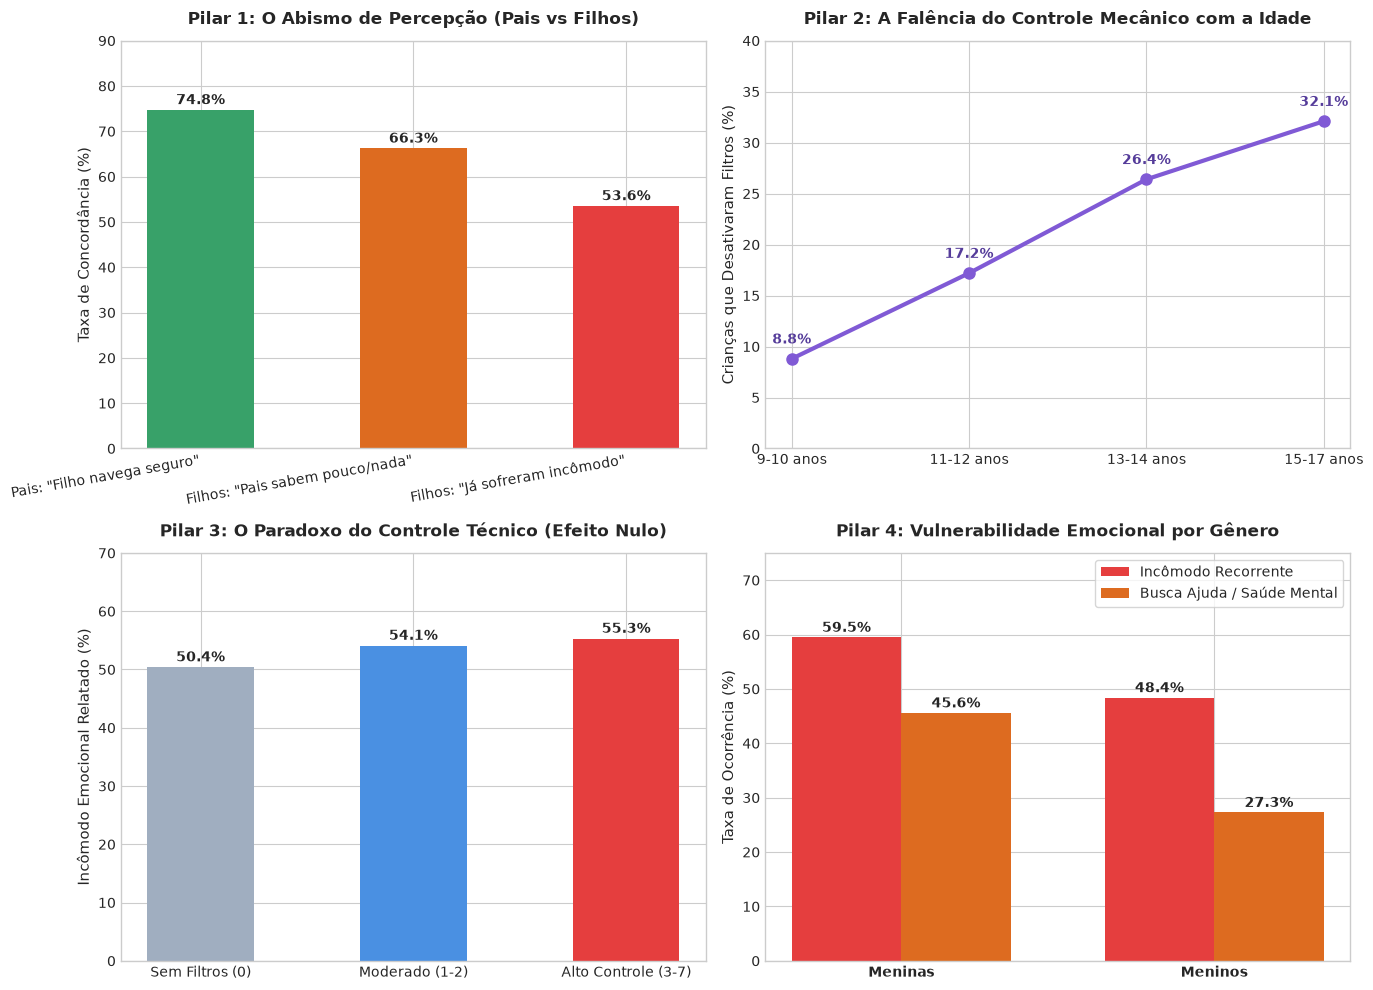

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Pilar 1: O Abismo da Percepção
percepcoes = ['Pais: "Filho navega seguro"', 'Filhos: "Pais sabem pouco/nada"', 'Filhos: "Já sofreram incômodo"']
tx_percep = [74.8, 66.3, 53.6]
cores_p1 = ['#38A169', '#DD6B20', '#E53E3E']
bars_p1 = axes[0, 0].bar(percepcoes, tx_percep, color=cores_p1, width=0.5)
axes[0, 0].set_ylabel('Taxa de Concordância (%)')
axes[0, 0].set_title('Pilar 1: O Abismo de Percepção (Pais vs Filhos)', fontweight='bold', pad=12)
axes[0, 0].set_ylim(0, 90)
for bar in bars_p1:
    h = bar.get_height()
    axes[0, 0].text(bar.get_x() + bar.get_width()/2, h + 1.2, f'{h:.1f}%', ha='center', fontweight='bold')
axes[0, 0].set_xticklabels(percepcoes, rotation=10, ha='right')

# 2. Pilar 2: A Curva de Evasão por Idade
faixas_ev = ['9-10 anos', '11-12 anos', '13-14 anos', '15-17 anos']
tx_ev = [8.8, 17.2, 26.4, 32.1]
axes[0, 1].plot(faixas_ev, tx_ev, marker='o', linewidth=3, markersize=8, color='#805AD5')
axes[0, 1].set_ylabel('Crianças que Desativaram Filtros (%)')
axes[0, 1].set_title('Pilar 2: A Falência do Controle Mecânico com a Idade', fontweight='bold', pad=12)
axes[0, 1].set_ylim(0, 40)
for i, v in enumerate(tx_ev):
    axes[0, 1].text(i, v + 1.5, f'{v:.1f}%', ha='center', fontweight='bold', color='#553C9A')

# 3. Pilar 3: O Paradoxo do Controle Técnico vs Incômodo
niveis_ctrl = ['Sem Filtros (0)', 'Moderado (1-2)', 'Alto Controle (3-7)']
tx_inc_ctrl = [50.4, 54.1, 55.3]
bars_p3 = axes[1, 0].bar(niveis_ctrl, tx_inc_ctrl, color=['#A0AEC0', '#4A90E2', '#E53E3E'], width=0.5)
axes[1, 0].set_ylabel('Incômodo Emocional Relatado (%)')
axes[1, 0].set_title('Pilar 3: O Paradoxo do Controle Técnico (Efeito Nulo)', fontweight='bold', pad=12)
axes[1, 0].set_ylim(0, 70)
for bar in bars_p3:
    h = bar.get_height()
    axes[1, 0].text(bar.get_x() + bar.get_width()/2, h + 1.0, f'{h:.1f}%', ha='center', fontweight='bold')

# 4. Pilar 4: Disparidade de Gênero
generos = ['Meninas', 'Meninos']
tx_incomodo_g = [59.5, 48.4]
tx_busca_g = [45.6, 27.3]
x_g = np.arange(len(generos))
w_g = 0.35
axes[1, 1].bar(x_g - w_g/2, tx_incomodo_g, width=w_g, label='Incômodo Recorrente', color='#E53E3E')
axes[1, 1].bar(x_g + w_g/2, tx_busca_g, width=w_g, label='Busca Ajuda / Saúde Mental', color='#DD6B20')
axes[1, 1].set_xticks(x_g)
axes[1, 1].set_xticklabels(generos, fontweight='bold')
axes[1, 1].set_ylabel('Taxa de Ocorrência (%)')
axes[1, 1].set_title('Pilar 4: Vulnerabilidade Emocional por Gênero', fontweight='bold', pad=12)
axes[1, 1].legend(frameon=True)
axes[1, 1].set_ylim(0, 75)
for i in x_g:
    axes[1, 1].text(i - w_g/2, tx_incomodo_g[i] + 1.0, f'{tx_incomodo_g[i]:.1f}%', ha='center', fontweight='bold')
    axes[1, 1].text(i + w_g/2, tx_busca_g[i] + 1.0, f'{tx_busca_g[i]:.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


### 5.3 Implicações Pedagógicas, Familiares e Regulatórias

#### 1. A Transição da Mediação Restritiva para a Mediação Capacitadora
Os dados provam que softwares espiões e bloqueadores de URL funcionam como um "placebo digital" para os adultos: oferecem tranquilidade aos pais, mas não protegem os filhos.
* **Recomendação Familiar:** O foco da parentalidade na era digital deve migrar do **controle mecânico unilateral** para a **mediação capacitadora (*enabling mediation*)**, baseada no diálogo constante, na negociação de limites transparentes e no acolhimento de vulnerabilidades sem a ameaça de punição imediata (confisco do aparelho).

#### 2. Atenção Urgente à Saúde Mental de Meninas
A forte sobre-representação das meninas nos relatos de incômodo ($aOR = 1,55$) e na busca por sofrimento emocional ($OR = 2,23$) reflete dinâmicas graves de pressão estética, cyberbullying, assédio e vigilância de imagem corporal em plataformas visuais (Instagram, TikTok).
* **Recomendação Escolar:** As escolas devem instituir programas permanentes de letramento emocional e digital direcionados a adolescentes, com foco em desconstrução de padrões tóxicos de autoimagem e canais confidenciais de apoio psicológico.

#### 3. Responsabilidade das Plataformas: *Safety by Design*
A segurança de crianças na internet não pode ser terceirizada unicamente para os pais:
* **Recomendação Regulatória:** As grandes plataformas e redes sociais devem adotar por padrão o princípio de **Segurança por Desenho (*Safety by Design*)**, desativando contas abertas por padrão para menores de 18 anos, bloqueando mecanismos de recomendação algorítmica viciantes e restringindo mensagens diretas de desconhecidos.

---
### 5.4 Limitações Metodológicas do Estudo
1. **Delineamento Transversal:** A pesquisa captura um único momento no tempo, impedindo inferências sobre trajetórias longitudinais de saúde mental.
2. **Viés de Desejabilidade Social:** Pais podem ter superestimado seu nível de controle ou segurança nas respostas para evitar julgamento moral.
3. **Natureza Subjetiva do Sofrimento:** A variável `M10_J` mede a percepção declarada de incômodo, que depende do repertório emocional e do nível de sensibilidade individual da criança.

---
### 5.5 Considerações Finais
Este estudo demonstrou o poder da estatística aplicada para desmistificar convicções enraizadas no senso comum. A comprovação da **nulidade do controle técnico** convida pais, educadores e legisladores a abandonarem a ilusão das barreiras mecânicas e investirem naquilo que os dados e a psicologia humana apontam como a verdadeira proteção: **o letramento crítico, o diálogo seguro e a regulação ética dos ambientes digitais**.

---
**PROJETO FINAL TIC KIDS CONCLUÍDO COM SUCESSO!**
